# TEWIWI BAKEHOUSE
## Machine Learning — Demand Forecasting

**Project:** Smart Order & Production Scheduling

**Objective:**
Develop a machine learning model to forecast bread demand for upcoming delivery schedules.

**Business Problem:**
Tewiwi Bakehouse needs better demand forecasting to support production planning, ingredient preparation, and delivery scheduling.

**Machine Learning Task:** Regression (check 4 models to see which one is the most suitable one)

The data is split chronologically, with the first 80% of calendar dates used for training and the last 20% for testing.

**Target Variable:** quantity_clean.
Model will forecast the number of units ordered for each SKU two days before the order date (order_date).

# Import Library & Data Loading

In [2]:
# Library untuk persiapan data, pelatihan, dan evaluasi
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.tsa.statespace.sarimax import SARIMAX
from xgboost import XGBRegressor

SEED = 42
HORIZON = 2

In [3]:
# Data Loading
# Membaca CSV sumber dan menyimpan salinan awal sebelum pembersihan.

file_id = "1ZuRu-NVbh_qVrlwq5fPQJzHTN5brxFUp"
url = f"https://drive.google.com/uc?export=download&id={file_id}"

df = pd.read_csv(url)

# Menyimpan salinan dataset asli
raw = df.copy()

print("Dataset loaded successfully!")
display(df.head(22))

Dataset loaded successfully!


,order_date,product_id,product_name,variant,unit_price,quantity
0,2025-01-01,TW001,Espresso Fudgy Brownies,Small,18000,12.0
1,2025-01-01,TW003,Blueberry Cheese Crumble,Standard,23000,5.0
2,2025-01-01,TW004,Korean Garlic Creamcheese,Standard,20000,6.0
3,2025-01-01,TW005,Cranberry Walnut Creamcheese,Standard,23000,9.0
4,2025-01-01,TW006,Dusty Choco Hazelnut,Standard,23000,8.0
5,2025-01-01,TW007,Paket Alit,PACKAGE,60000,4.0
6,2025-01-01,TW008,Salt Bread Original,Standard,18000,0.0
7,2025-01-01,TW009,Sei Cheese Salt Bread,Standard,23000,7.0
8,2025-01-01,TW010,Shokupan Loaf,Standard,25000,5.0
9,2025-01-01,TW011,Country Bread,Standard,38000,5.0


In [4]:
# Cek Informasi Dataset
# Memeriksa ukuran, kolom, dan tipe data sebelum transformasi.

print("DATASET INFORMATION")
print("=" * 50)

df.info()

print("\nDATA TYPES")
display(df.dtypes)

print("\nDESCRIPTIVE STATISTICS")
display(df.describe(include="all"))

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3986 entries, 0 to 3985
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   order_date    3986 non-null   object 
 1   product_id    3986 non-null   object 
 2   product_name  3986 non-null   object 
 3   variant       3986 non-null   object 
 4   unit_price    3986 non-null   int64  
 5   quantity      3901 non-null   float64
dtypes: float64(1), int64(1), object(4)
memory usage: 187.0+ KB

DATA TYPES


,0
order_date,object
product_id,object
product_name,object
variant,object
unit_price,int64
quantity,float64



DESCRIPTIVE STATISTICS


,order_date,product_id,product_name,variant,unit_price,quantity
count,3986,3986,3986,3986,3986.000000,3901.000000
unique,365,11,10,16,NaN,NaN
top,2025-12-31,TW011,Espresso Fudgy Brownies,Standard,NaN,NaN
freq,11,365,722,2757,NaN,NaN
mean,NaN,NaN,NaN,NaN,30264.174611,10.300179
std,NaN,NaN,NaN,NaN,15351.758625,6.352498
min,NaN,NaN,NaN,NaN,18000.000000,-1.000000
25%,NaN,NaN,NaN,NaN,20000.000000,6.000000
50%,NaN,NaN,NaN,NaN,23000.000000,10.000000
75%,NaN,NaN,NaN,NaN,38000.000000,14.000000


In [5]:
# Menampilkan tipe tiap kolom untuk membantu pemeriksaan format.

print(df.dtypes)

order_date       object
product_id       object
product_name     object
variant          object
unit_price        int64
quantity        float64
dtype: object


# Data Preprocessing

## Data Cleaning

In [7]:
# Cek Kondisi Data
# Menghitung nilai kosong dan duplikasi serta meninjau rentang dan isi data.

print("MISSING VALUES")
display(df.isnull().sum())

print("\nDUPLICATED ROWS")
print(df.duplicated().sum())

print("\nDUPLICATED DATE–SOURCE PRODUCT ID")
print(
    df.duplicated(
        subset=["order_date", "product_id"]
    ).sum()
)

quantity_check = pd.to_numeric(df["quantity"], errors="coerce")

print("\nNEGATIVE QUANTITY")
print((quantity_check < 0).sum())

print("\nZERO QUANTITY")
print((quantity_check == 0).sum())

print("\nUNIQUE PRODUCTS")
print(df["product_id"].nunique())

print("\nUNIQUE DATES")
print(df["order_date"].nunique())

MISSING VALUES


,0
order_date,0
product_id,0
product_name,0
variant,0
unit_price,0
quantity,85



DUPLICATED ROWS
0

DUPLICATED DATE–SOURCE PRODUCT ID
0

NEGATIVE QUANTITY
63

ZERO QUANTITY
102

UNIQUE PRODUCTS
11

UNIQUE DATES
365


In [8]:
# Tinjau struktur data kerja
# Menampilkan jumlah baris dan kolom yang akan diproses.

print(f"Data kerja: {df.shape[0]} baris, {df.shape[1]} kolom")

Data kerja: 3986 baris, 6 kolom


In [9]:
# Menetapkan pasangan tanggal dan ID produk sebagai kunci data sumber.
# product_id pada CSV merupakan ID SKU sumber.

source_day_key = ["order_date", "product_id"]

In [10]:
# Normalisasi tanggal dan angka
# Menyeragamkan tipe data dan memeriksa kunci kosong atau duplikat.

df["order_date"] = pd.to_datetime(df["order_date"], errors="raise").dt.normalize()
for col in ["product_id", "product_name", "variant"]:
    df[col] = df[col].astype("string").str.strip().replace("", pd.NA)

if df[source_day_key].isna().any().any():
    raise ValueError("Tanggal atau ID produk sumber kosong.")
if df.duplicated(source_day_key).any():
    raise ValueError("Kunci tanggal–ID produk sumber berulang setelah normalisasi.")

df["unit_price"] = pd.to_numeric(df["unit_price"], errors="coerce")
df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce").replace(
    [np.inf, -np.inf], np.nan
)
display(df.dtypes)

,0
order_date,datetime64[ns]
product_id,string[python]
product_name,string[python]
variant,string[python]
unit_price,int64
quantity,float64


In [11]:
# Standarisasi Kategori
# Menyeragamkan penulisan varian agar bisa dicocokkan dengan katalog.

df["variant"] = (
    df["variant"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.title()
)

print("Unique variants after standardization:")

display(
    sorted(df["variant"].dropna().unique())
)

Unique variants after standardization:


['Large', 'Package', 'Small', 'Standard']

In [12]:
# Pratinjau data
# Memeriksa beberapa baris setelah standardisasi.

df.head()

,order_date,product_id,product_name,variant,unit_price,quantity
0,2025-01-01,TW001,Espresso Fudgy Brownies,Small,18000,12.0
1,2025-01-01,TW003,Blueberry Cheese Crumble,Standard,23000,5.0
2,2025-01-01,TW004,Korean Garlic Creamcheese,Standard,20000,6.0
3,2025-01-01,TW005,Cranberry Walnut Creamcheese,Standard,23000,9.0
4,2025-01-01,TW006,Dusty Choco Hazelnut,Standard,23000,8.0


In [13]:
# Menangani Missing dan Negative Quantity
# Membedakan kuantitas valid, kosong, dan negatif serta mengosongkan kuantitas negatif.

df["quality_issue"] = np.select(
    [
        df["quantity"].isna(),
        df["quantity"] < 0
    ],
    [
        "missing_quantity",
        "negative_quantity"
    ],
    default="valid"
)

df["quantity_clean"] = df["quantity"].mask(
    df["quantity"] < 0
)

print("DATA QUALITY SUMMARY")

display(
    df["quality_issue"]
    .value_counts()
    .rename_axis("quality_issue")
    .reset_index(name="total")
)

print("\nMissing values after cleaning:")

print(df["quantity_clean"].isna().sum())

DATA QUALITY SUMMARY


,quality_issue,total
0,valid,3838
1,missing_quantity,85
2,negative_quantity,63



Missing values after cleaning:
148


In [14]:
# Katalog ID sumber dan pemetaan
# Menetapkan identitas SKU dan memetakan dua ukuran brownies ke satu produk stok.

# 1. Ambil ID, nama, dan varian produk. Hapus baris katalog yang identik,
# lalu ganti nama product_id menjadi sku_id dan urutkan berdasarkan ID.
catalog = (
    df[["product_id", "product_name", "variant"]].drop_duplicates()
    .rename(columns={"product_id": "sku_id"}).sort_values("sku_id").reset_index(drop=True)
)

# 2. Periksa keunikan SKU dan kelengkapan nama produk
if catalog["sku_id"].duplicated().any() or catalog["product_name"].isna().any():
    raise ValueError("Setiap SKU perlu satu nama produk dan varian yang konsisten.")

# 3. Ambil kedua varian Espresso Fudgy Brownies
brownies_name = "Espresso Fudgy Brownies"
brownies = catalog.loc[catalog["product_name"].eq(brownies_name)]

# 4. Pastikan ID SKU cocok dengan ukuran brownies
if brownies.set_index("sku_id")["variant"].to_dict() != {"TW001": "Small", "TW002": "Large"}:
    raise ValueError("Periksa pemetaan varian Espresso Fudgy Brownies.")

# Pemetaan stok dipakai setelah forecast. Kedua SKU tetap ada di katalog demand.
# 5. Tetapkan ID produk untuk penggabungan kebutuhan stok TW001 dan TW002 tetap diprediksi per SKU.
# Setelah forecast, keduanya dijumlahkan sebagai satu produk stok dengan ID TW001.
catalog["stock_product_id"] = catalog["sku_id"].replace({"TW002": "TW001"})

display(catalog)

,sku_id,product_name,variant,stock_product_id
0,TW001,Espresso Fudgy Brownies,Small,TW001
1,TW002,Espresso Fudgy Brownies,Large,TW001
2,TW003,Blueberry Cheese Crumble,Standard,TW003
3,TW004,Korean Garlic Creamcheese,Standard,TW004
4,TW005,Cranberry Walnut Creamcheese,Standard,TW005
5,TW006,Dusty Choco Hazelnut,Standard,TW006
6,TW007,Paket Alit,Package,TW007
7,TW008,Salt Bread Original,Standard,TW008
8,TW009,Sei Cheese Salt Bread,Standard,TW009
9,TW010,Shokupan Loaf,Standard,TW010


In [15]:
# Deret harian per SKU
# Menyiapkan kuantitas dan status kualitas per tanggal dan SKU.
# Ambil target harian setiap SKU tanpa agregasi antarvarian.

sku_day_key = ["order_date", "sku_id"]
sku_daily = (
    df.rename(columns={"product_id": "sku_id"})
    .set_index(sku_day_key)[["quantity_clean", "quality_issue"]]
)

In [16]:
# Membuat satu baris per tanggal dan SKU, termasuk kombinasi tanpa data.

# 1. Buat kalender dari tanggal pertama hingga tanggal terakhir
date_range = pd.date_range(df["order_date"].min(), df["order_date"].max(), freq="D")

# 2. Bentuk semua pasangan tanggal dan SKU
full_index = pd.MultiIndex.from_product(
    [date_range, catalog["sku_id"]], names=sku_day_key
)
# 3. Masukkan data penjualan ke kalender lengkap
panel = sku_daily.reindex(full_index).reset_index()

# 4. Tandai pasangan tanggal–SKU tanpa baris sumber
panel["quality_issue"] = panel["quality_issue"].fillna("missing_sku_day")

# 5. Tambahkan informasi produk dari katalog
panel = panel.merge(catalog, on="sku_id", validate="many_to_one")

# 6. Urutkan kalender per SKU dan tanggal
panel = panel.sort_values(["sku_id", "order_date"]).reset_index(drop=True)

print(f"Total baris tanggal–SKU: {len(panel)}")
display(panel["quality_issue"].value_counts())

Total baris tanggal–SKU: 4015


,count
quality_issue,
valid,3838
missing_quantity,85
negative_quantity,63
missing_sku_day,29


In [17]:
from pathlib import Path

sku_columns = sorted(catalog["sku_id"].unique())

time_series_final = (
    panel.pivot(
        index="order_date",
        columns="sku_id",
        values="quantity_clean",
    )
    .sort_index()
    .reindex(columns=sku_columns)
    .rename_axis(index="order_date", columns=None)
)

output_path = Path("time_series_final.csv")

time_series_final.to_csv(
    output_path,
    index=True,
    date_format="%Y-%m-%d",
    na_rep="",
    encoding="utf-8",
)

print(f"File: {output_path.resolve()}")
print(f"Jumlah tanggal: {len(time_series_final)}")
print(f"Jumlah SKU: {len(sku_columns)}")
print(f"Periode: {time_series_final.index.min():%Y-%m-%d} sampai "
      f"{time_series_final.index.max():%Y-%m-%d}")
print(f"Jumlah nilai kosong: {time_series_final.isna().sum().sum()}")

display(time_series_final.head().reset_index())

File: /content/time_series_final.csv
Jumlah tanggal: 365
Jumlah SKU: 11
Periode: 2025-01-01 sampai 2025-12-31
Jumlah nilai kosong: 177


,order_date,TW001,TW002,TW003,TW004,TW005,TW006,TW007,TW008,TW009,TW010,TW011
0,2025-01-01,12.0,NaN,5.0,6.0,9.0,8.0,4.0,0.0,7.0,5.0,5.0
1,2025-01-02,14.0,6.0,5.0,11.0,NaN,9.0,3.0,18.0,5.0,7.0,11.0
2,2025-01-03,13.0,7.0,9.0,9.0,10.0,7.0,7.0,17.0,10.0,NaN,4.0
3,2025-01-04,18.0,10.0,14.0,14.0,7.0,9.0,15.0,14.0,10.0,15.0,15.0
4,2025-01-05,10.0,7.0,15.0,14.0,14.0,10.0,11.0,12.0,13.0,21.0,15.0


In [18]:
from google.colab import files

files.download(str(output_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
time_series_interpolated_full = (
    time_series_final
    .interpolate(method="time", limit_area="inside")
    .ffill()
    .bfill()
)

time_series_interpolated_full.to_csv(
    "time_series_interpolated_full.csv",
    index=True,
    date_format="%Y-%m-%d",
    na_rep="",
    encoding="utf-8",
)

In [20]:
# Menampilkan nama produk unik untuk pemeriksaan katalog.

print(df['product_name'].unique())

<StringArray>
[     'Espresso Fudgy Brownies',     'Blueberry Cheese Crumble',
    'Korean Garlic Creamcheese', 'Cranberry Walnut Creamcheese',
         'Dusty Choco Hazelnut',                   'Paket Alit',
          'Salt Bread Original',        'Sei Cheese Salt Bread',
                'Shokupan Loaf',                'Country Bread']
Length: 10, dtype: string


## Data Analysis (EDA)

In [21]:
# Pemetaan dua ukuran brownies
# Menampilkan SKU brownies yang terpisah untuk forecast dan digabung untuk stok.

# Satu produk untuk stok, dua SKU untuk penjualan.
display(catalog.loc[catalog["product_name"].eq(brownies_name)])

,sku_id,product_name,variant,stock_product_id
0,TW001,Espresso Fudgy Brownies,Small,TW001
1,TW002,Espresso Fudgy Brownies,Large,TW001


In [22]:
# Meninjau urutan baris tanggal dan SKU setelah kalender dilengkapi.

display(panel.head(20))

,order_date,sku_id,quantity_clean,quality_issue,product_name,variant,stock_product_id
0,2025-01-01,TW001,12.0,valid,Espresso Fudgy Brownies,Small,TW001
1,2025-01-02,TW001,14.0,valid,Espresso Fudgy Brownies,Small,TW001
2,2025-01-03,TW001,13.0,valid,Espresso Fudgy Brownies,Small,TW001
3,2025-01-04,TW001,18.0,valid,Espresso Fudgy Brownies,Small,TW001
4,2025-01-05,TW001,10.0,valid,Espresso Fudgy Brownies,Small,TW001
5,2025-01-06,TW001,10.0,valid,Espresso Fudgy Brownies,Small,TW001
6,2025-01-07,TW001,18.0,valid,Espresso Fudgy Brownies,Small,TW001
7,2025-01-08,TW001,NaN,negative_quantity,Espresso Fudgy Brownies,Small,TW001
8,2025-01-09,TW001,14.0,valid,Espresso Fudgy Brownies,Small,TW001
9,2025-01-10,TW001,15.0,valid,Espresso Fudgy Brownies,Small,TW001


## Batas Data EDA dan Split Kronologis (Train 80, Test 20)

In [23]:
# Split kronologis dan batas informasi H−2
# Menetapkan awal test dan tanggal terakhir informasi untuk forecast test pertama.

# 1. Susun daftar tanggal unik dari yang paling awal
# Satu tanggal muncul untuk banyak SKU. Split dihitung per hari kalender.
dates = pd.DatetimeIndex(panel["order_date"].drop_duplicates().sort_values())

# 2. Tentukan posisi awal test pada pembagian 80:20
split_idx = int(len(dates) * 0.8)

# 3. Periksa kecukupan tanggal untuk split dan horizon forecast
if split_idx < HORIZON or split_idx >= len(dates):
    raise ValueError("Jumlah tanggal belum cukup untuk split dan forecast H−2.")

# 4. Tetapkan tanggal target test pertama dan tanggal forecast dibuat
split_date = dates[split_idx]
first_origin = split_date - pd.Timedelta(days=HORIZON)

# 5. Batasi data EDA sampai tanggal forecast pertama
eda_panel = panel.loc[panel["order_date"].le(first_origin)].copy()

print(f"Training kalender: {split_idx} hari, {dates[0]:%Y-%m-%d} s.d. {dates[split_idx - 1]:%Y-%m-%d}")
print(f"Testing kalender: {len(dates) - split_idx} hari, {split_date:%Y-%m-%d} s.d. {dates[-1]:%Y-%m-%d}")
print(f"Batas aktual untuk fit awal dan EDA: {first_origin:%Y-%m-%d}")

Training kalender: 292 hari, 2025-01-01 s.d. 2025-10-19
Testing kalender: 73 hari, 2025-10-20 s.d. 2025-12-31
Batas aktual untuk fit awal dan EDA: 2025-10-18


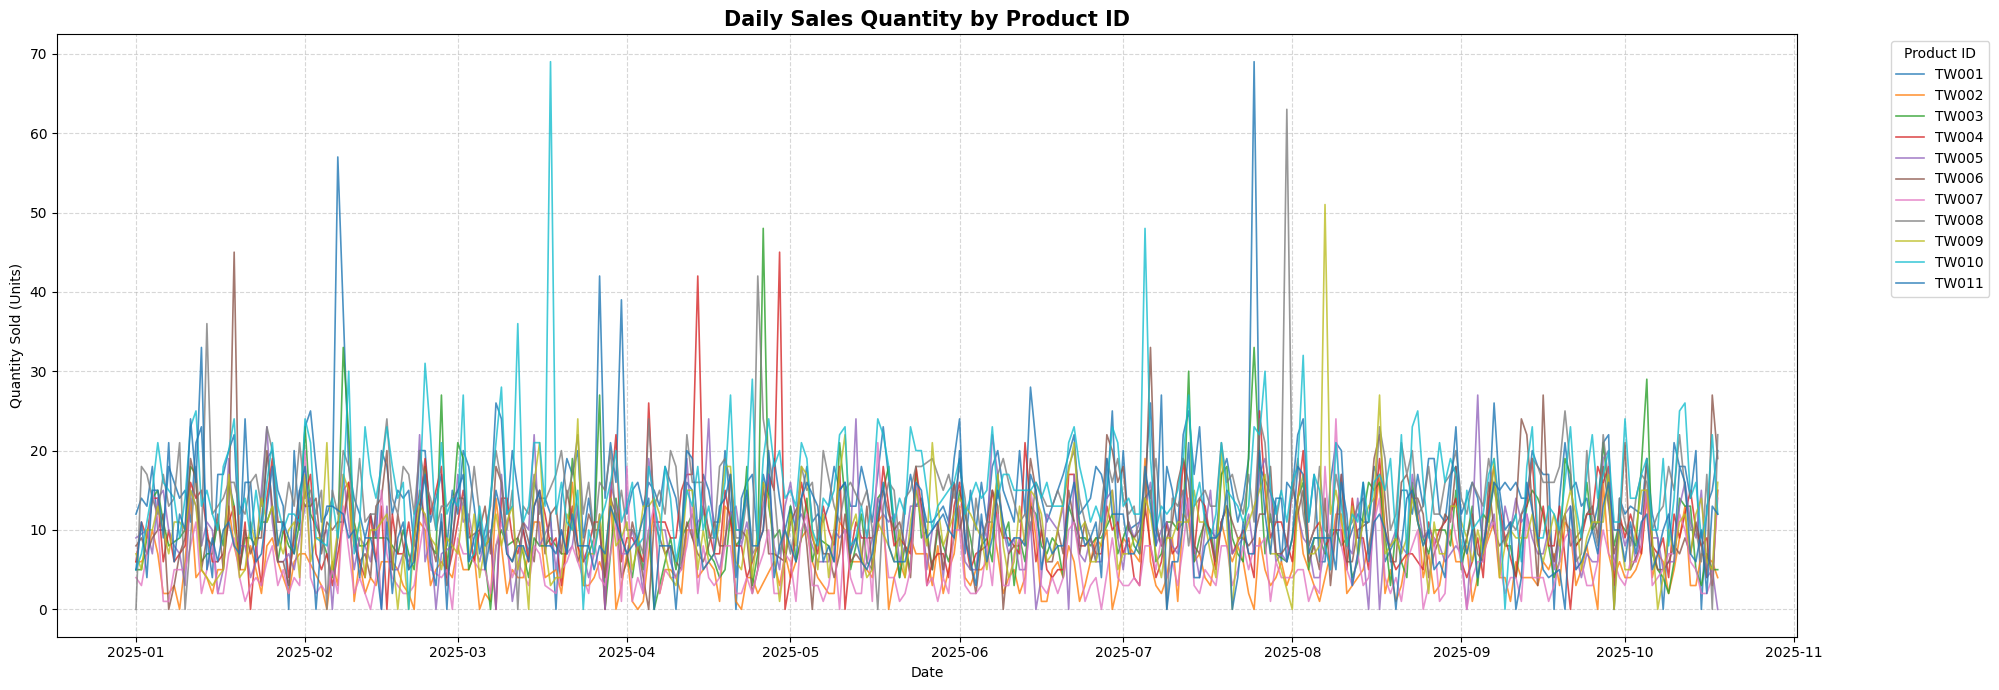

In [24]:
# Visualisasi Daily Sales Time Series per SKU
# Melihat perubahan jumlah penjualan setiap produk sampai batas informasi fit awal.
# Membentuk deret harian EDA dengan satu baris per tanggal dan produk.

# 1. Bentuk deret harian dengan satu kolom per SKU
# Tanggal menjadi baris, SKU menjadi kolom, dan kuantitas menjadi isi tabel.
# Urutkan tanggal sebelum mengisi celah dan menggambar garis.
time_series_data = (
    eda_panel.pivot(
        index="order_date",
        columns="sku_id",
        values="quantity_clean"
    )
    .sort_index()
)
# Melakukan interpolasi linear untuk mengisi nilai NaN pada data time series
# dan mengisi sisa nilai kosong di batas ujung (jika ada) dengan ffill dan bfill
time_series_interpolated = (
    time_series_data
    .interpolate(method="time", limit_area="inside")
    .ffill()
    .bfill()
)

# 3. Membuat plot time series. Siapkan ukuran grafik
plt.figure(figsize=(20, 7))

# 4. Gambar satu garis untuk setiap SKU
for sku_id in time_series_interpolated.columns:
    plt.plot(
        time_series_interpolated.index,
        time_series_interpolated[sku_id],
        label=sku_id,
        linewidth=1.2,
        alpha=0.8,
    )

# 5. Beri judul dan nama sumbu
plt.title(
    "Daily Sales Quantity by Product ID",
    fontsize=15,
    fontweight="bold"
)
plt.xlabel("Date")
plt.ylabel("Quantity Sold (Units)")

# 6. Letakkan legenda di luar grafik sebelah kanan
plt.legend(
    title="Product ID",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

# 7. Tambahkan grid, rapikan tata letak, dan tampilkan grafik
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [25]:
# Cek Time Series Data
# Menampilkan deret harian yang masih menyimpan nilai kosong asli.

time_series_data

sku_id,TW001,TW002,TW003,TW004,TW005,TW006,TW007,TW008,TW009,TW010,TW011
order_date,,,,,,,,,,,
2025-01-01,12.0,NaN,5.0,6.0,9.0,8.0,4.0,0.0,7.0,5.0,5.0
2025-01-02,14.0,6.0,5.0,11.0,NaN,9.0,3.0,18.0,5.0,7.0,11.0
2025-01-03,13.0,7.0,9.0,9.0,10.0,7.0,7.0,17.0,10.0,NaN,4.0
2025-01-04,18.0,10.0,14.0,14.0,7.0,9.0,15.0,14.0,10.0,15.0,15.0
2025-01-05,10.0,7.0,15.0,14.0,14.0,10.0,11.0,12.0,13.0,21.0,15.0
...,...,...,...,...,...,...,...,...,...,...,...
2025-10-14,20.0,3.0,5.0,10.0,9.0,11.0,5.0,10.0,12.0,16.0,6.0
2025-10-15,0.0,7.0,3.0,8.0,15.0,8.0,2.0,6.0,14.0,9.0,10.0
2025-10-16,13.0,NaN,7.0,9.0,4.0,4.0,2.0,17.0,6.0,12.0,2.0


In [26]:
# Menghitung nilai kosong sebelum pengisian untuk visualisasi.

time_series_data.isna().sum()

,0
sku_id,
TW001,16
TW002,14
TW003,18
TW004,20
TW005,9
TW006,11
TW007,11
TW008,12
TW009,16


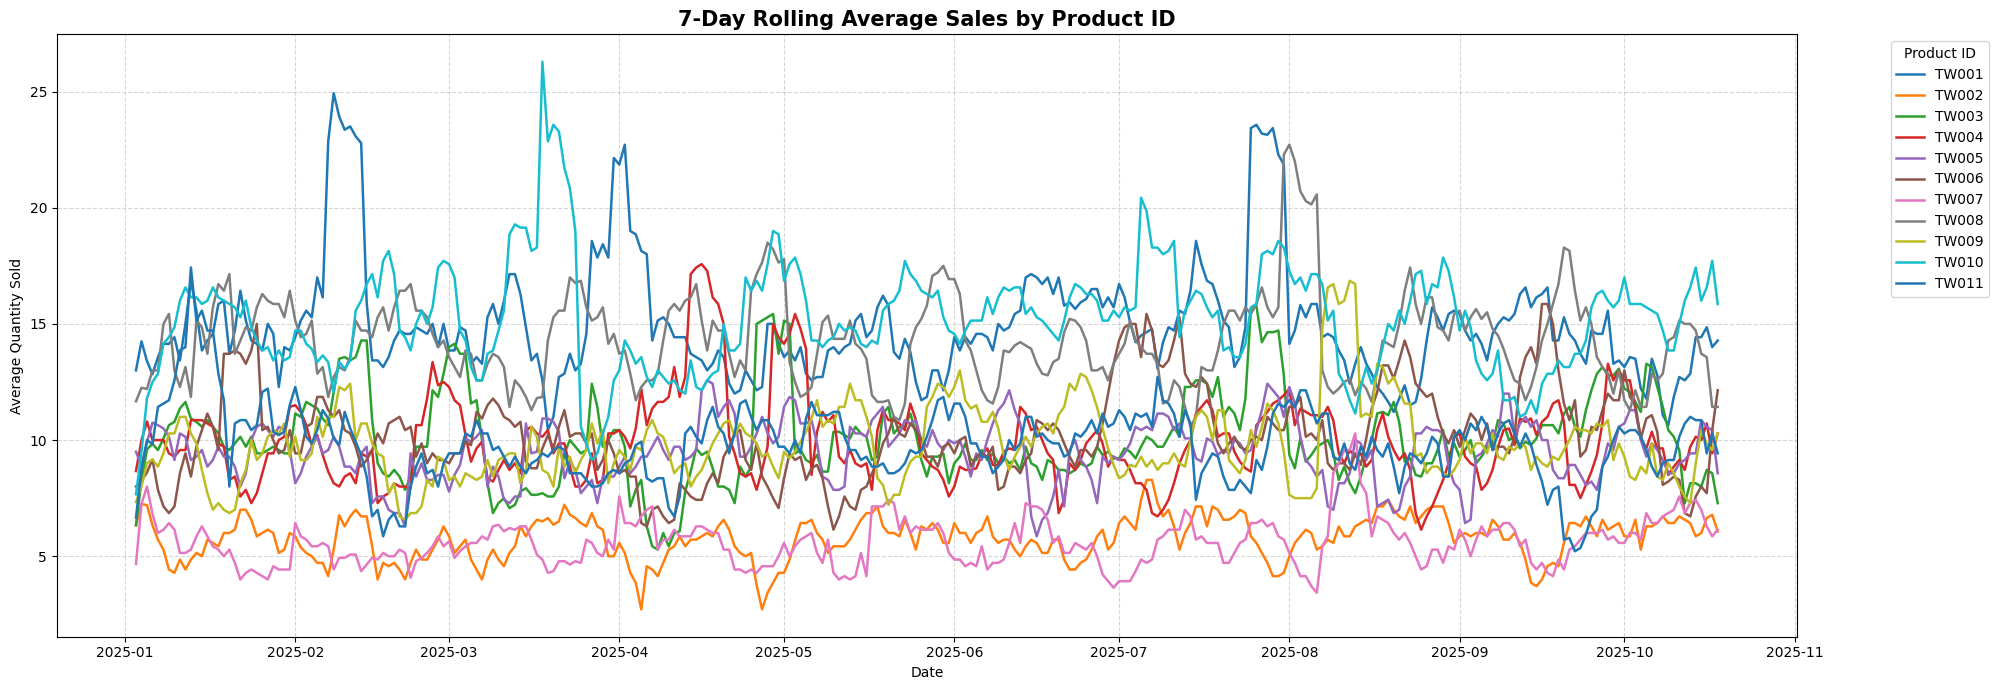

In [27]:
# ROLLING AVERAGE VISUALIZATION
# Memperjelas tren penjualan dengan menghitung rata-rata bergerak tujuh hari.

# 1. Menghitung rata-rata bergerak 7 hari dari data yang sudah diinterpolasi sebelumnya.
# Dua hari pertama tetap kosong karena min_periods=3 memerlukan minimal tiga nilai.

rolling_avg = time_series_interpolated.rolling(window=7, min_periods=3).mean()

plt.figure(figsize=(20, 7))

# 2. Gambar satu garis rata-rata bergerak untuk setiap SKU
for product in rolling_avg.columns:
    plt.plot(
        rolling_avg.index,
        rolling_avg[product],
        label=product,
        linewidth=1.8
    )

plt.title(
    "7-Day Rolling Average Sales by Product ID",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Date")
plt.ylabel("Average Quantity Sold")

plt.legend(
    title="Product ID",
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

# 3. Tambahkan grid, rapikan tata letak, dan tampilkan grafik
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

,total_sales,avg_daily_sales,median_sales,std_sales,valid_days
sku_id,,,,,
TW010,4348.0,15.256140,14.0,6.691465,285
TW001,4109.0,14.941818,14.0,6.831942,275
TW008,3981.0,14.268817,14.0,5.861973,279
TW006,2881.0,10.289286,10.0,5.201174,280
TW003,2733.0,10.010989,9.0,5.546252,273
TW011,2710.0,9.783394,9.0,4.915593,277
TW009,2709.0,9.850909,10.0,5.105774,275
TW004,2707.0,9.988930,9.0,5.337834,271
TW005,2668.0,9.460993,9.0,4.635493,282


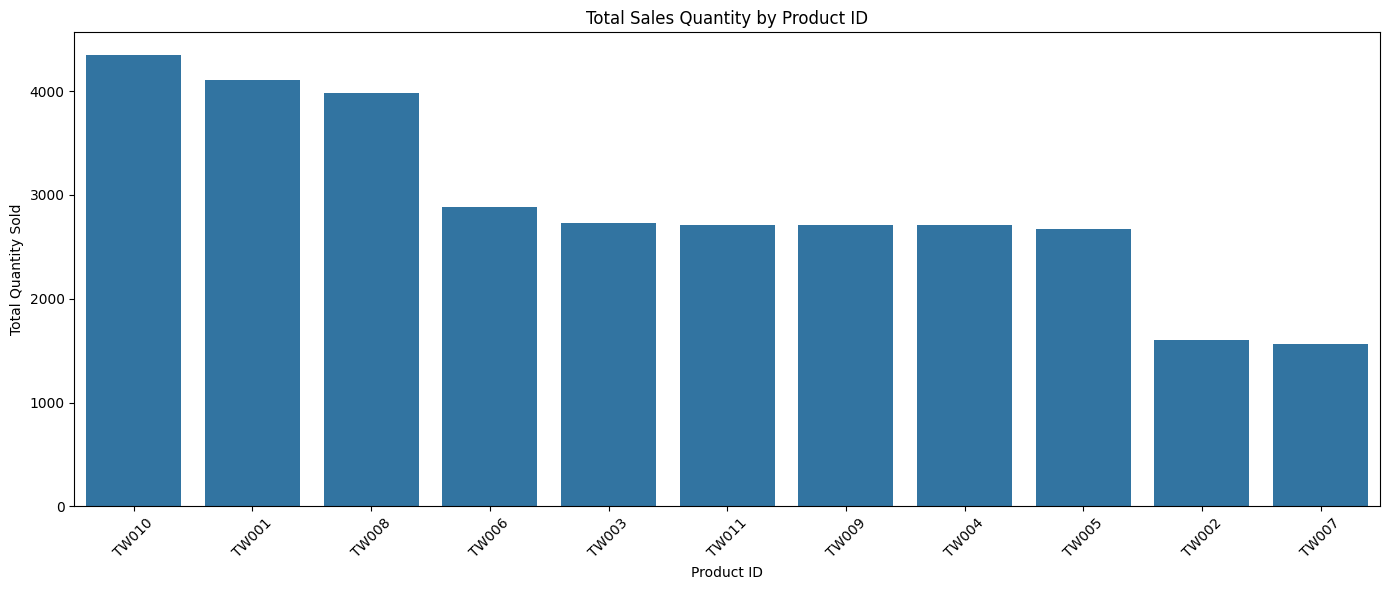

In [28]:
# SALES DISTRIBUTION BY Product ID
# Membandingkan karakteristik penjualan setiap Product ID

product_summary = (
    eda_panel.groupby("sku_id")
    .agg(
        total_sales=("quantity_clean", "sum"),
        avg_daily_sales=("quantity_clean", "mean"),
        median_sales=("quantity_clean", "median"),
        std_sales=("quantity_clean", "std"),
        valid_days=("quantity_clean", "count")
    )
    .sort_values(
        "total_sales",
        ascending=False
    )
)

display(product_summary)

plt.figure(figsize=(14, 6))

sns.barplot(
    data=product_summary.reset_index(),
    x="sku_id",
    y="total_sales"
)

plt.title("Total Sales Quantity by Product ID")
plt.xlabel("Product ID")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

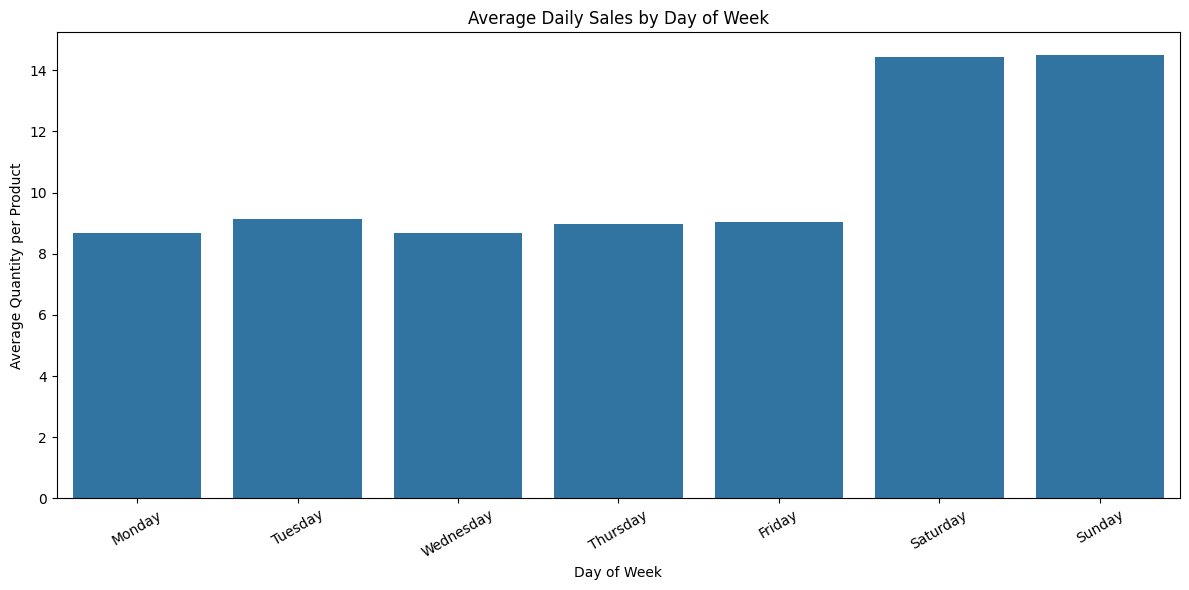

,day,average_quantity
0,Monday,8.692130
1,Tuesday,9.127021
2,Wednesday,8.668919
3,Thursday,8.960829
4,Friday,9.038549
5,Saturday,14.423341
6,Sunday,14.512702


In [29]:
# WEEKLY SALES PATTERN
# Mengetahui apakah terdapat perbedaan penjualan berdasarkan hari dalam minggu

eda_df = eda_panel.copy()

eda_df["day_of_week"] = (
    eda_df["order_date"].dt.dayofweek
)

day_names = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

weekly_sales = (
    eda_df.groupby("day_of_week")["quantity_clean"]
    .mean()
    .reindex(range(7))
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=day_names,
    y=weekly_sales.values
)

plt.title("Average Daily Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Average Quantity per Product")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(
    pd.DataFrame({
        "day": day_names,
        "average_quantity": weekly_sales.values
    })
)

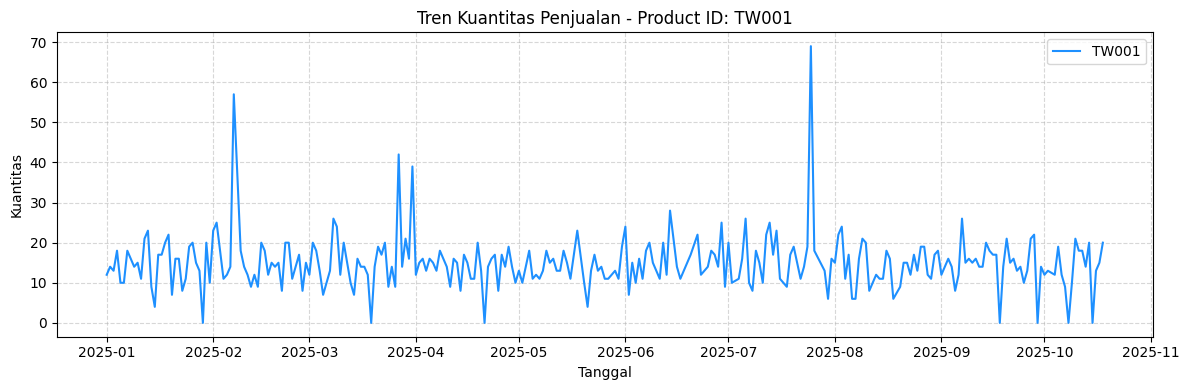

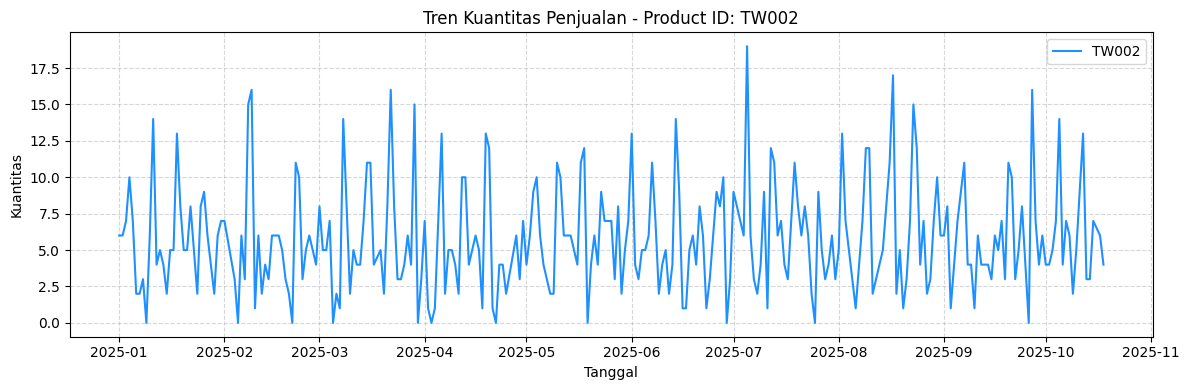

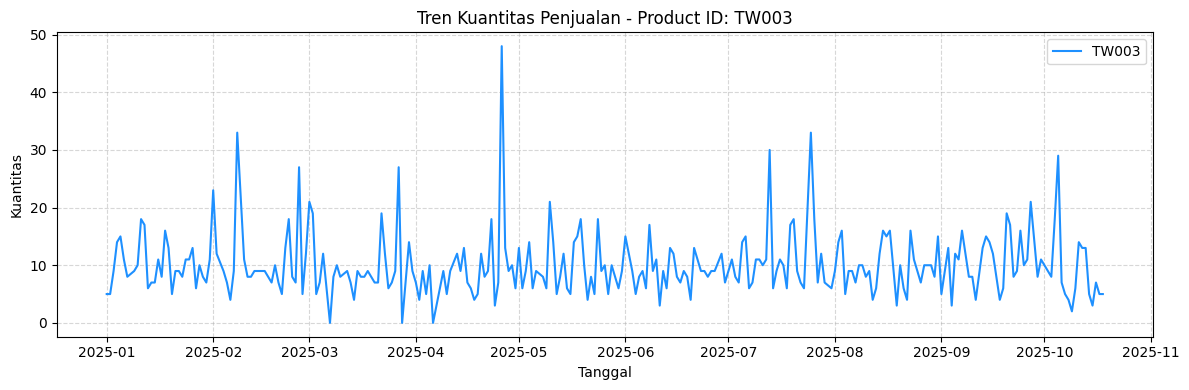

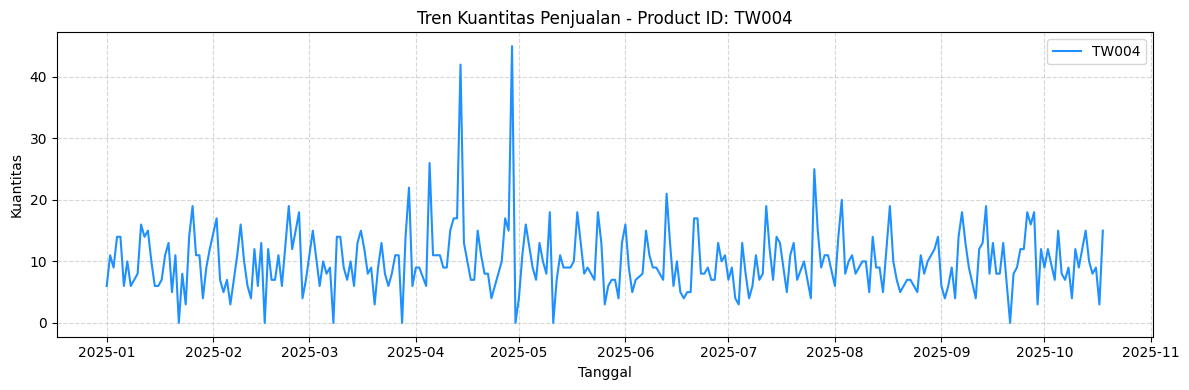

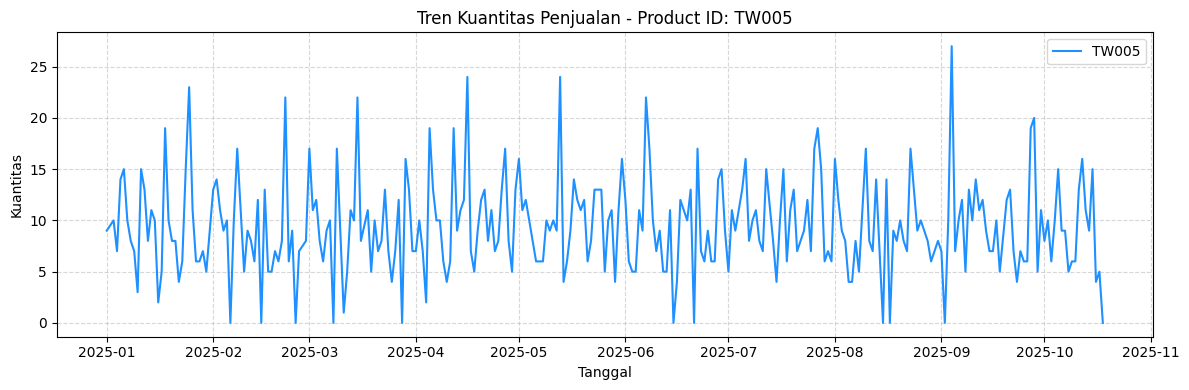

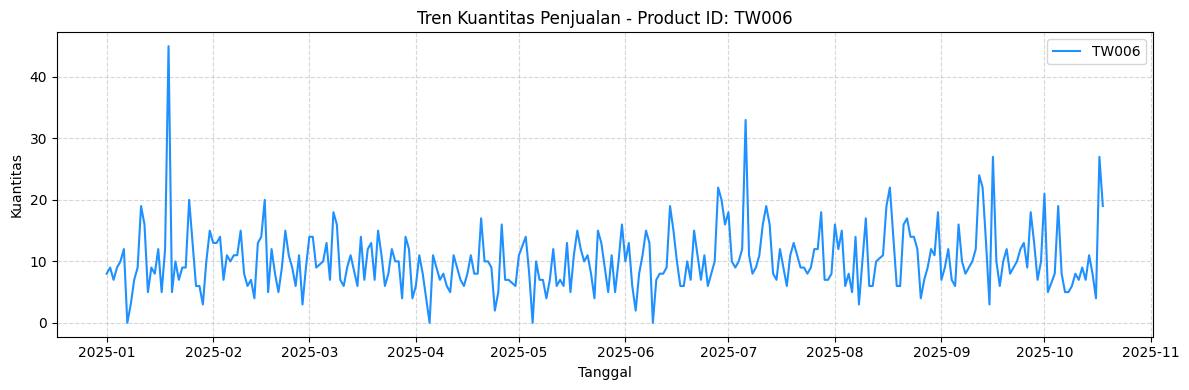

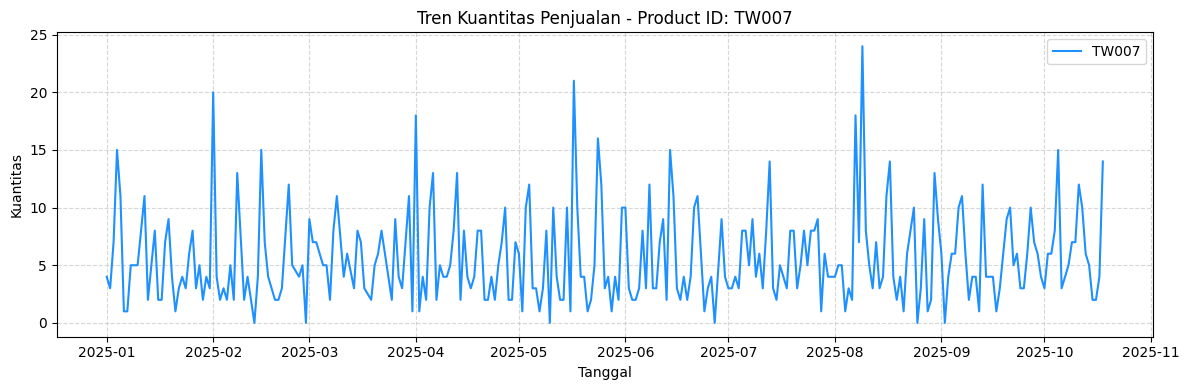

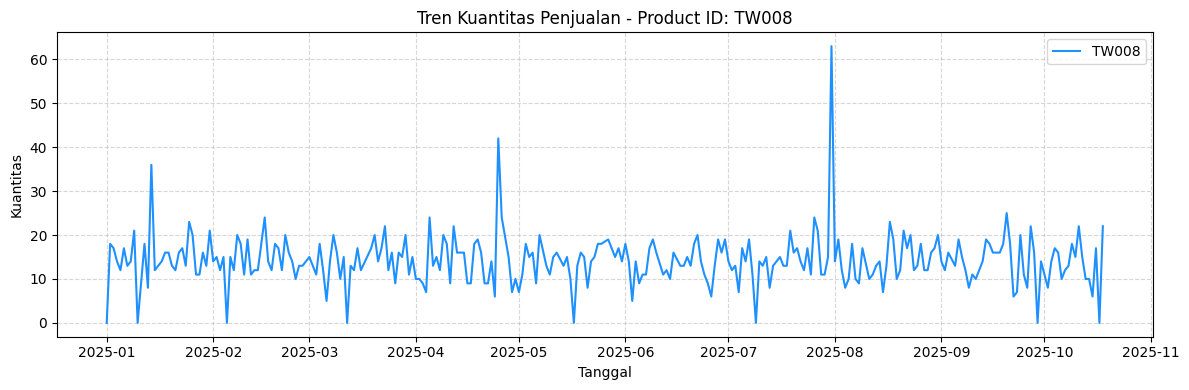

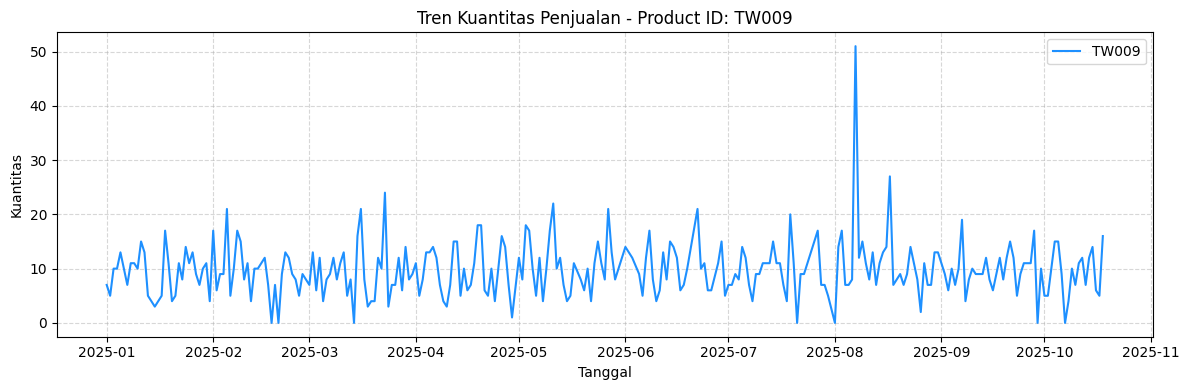

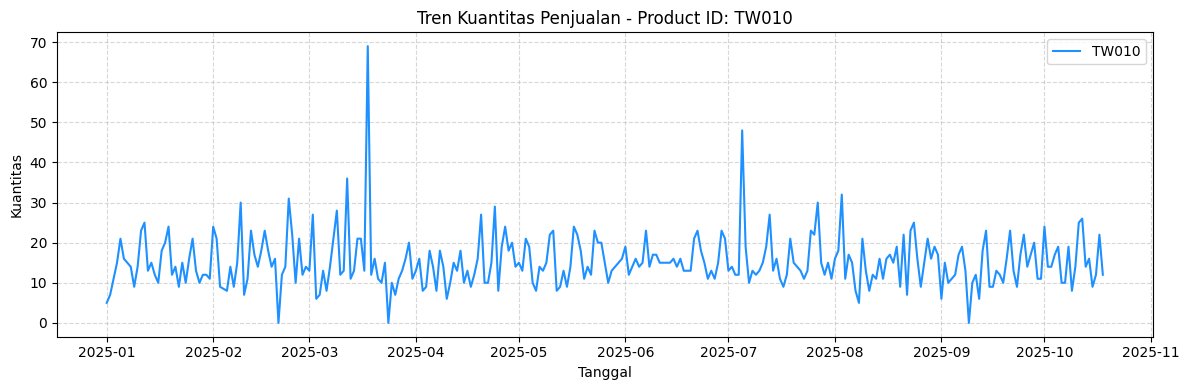

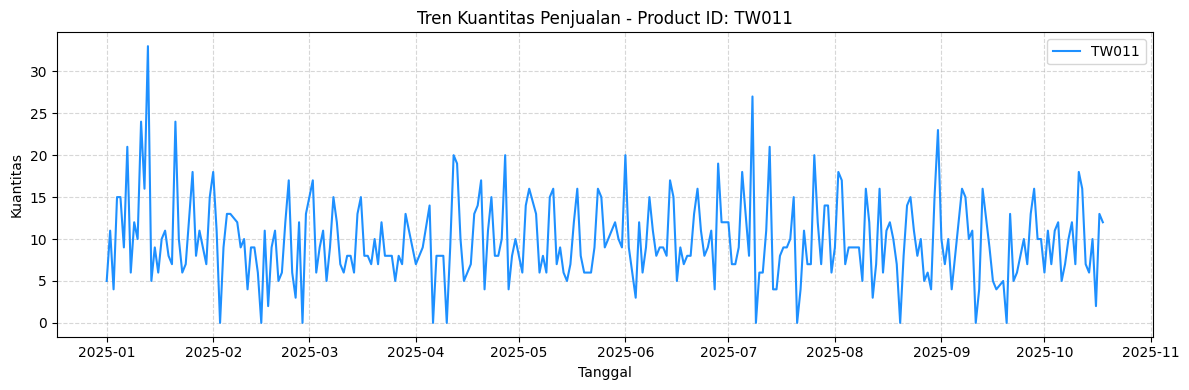

In [30]:
# Grafik tren per SKU
# Menggambar deret terinterpolasi pada grafik terpisah agar pola tiap SKU terbaca.

# Loop untuk menampilkan plot masing-masing sku_id satu per satu
for sku_id in time_series_interpolated.columns:
    plt.figure(figsize=(12, 4))
    plt.plot(time_series_interpolated.index, time_series_interpolated[sku_id], color='dodgerblue', label=sku_id)
    plt.title(f'Tren Kuantitas Penjualan - Product ID: {sku_id}', fontsize=12)
    plt.xlabel('Tanggal', fontsize=10)
    plt.ylabel('Kuantitas', fontsize=10)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.legend()
    plt.tight_layout()
    plt.show()

## Missing Value & Outlier

MISSING VALUES PER PRODUCT ID


,sku_id,missing_quantity
0,TW001,16
1,TW002,14
2,TW003,18
3,TW004,20
4,TW005,9
5,TW006,11
6,TW007,11
7,TW008,12
8,TW009,16
9,TW010,6


Lower Bound: -6.0
Upper Bound: 26.0
Potential Outliers: 38


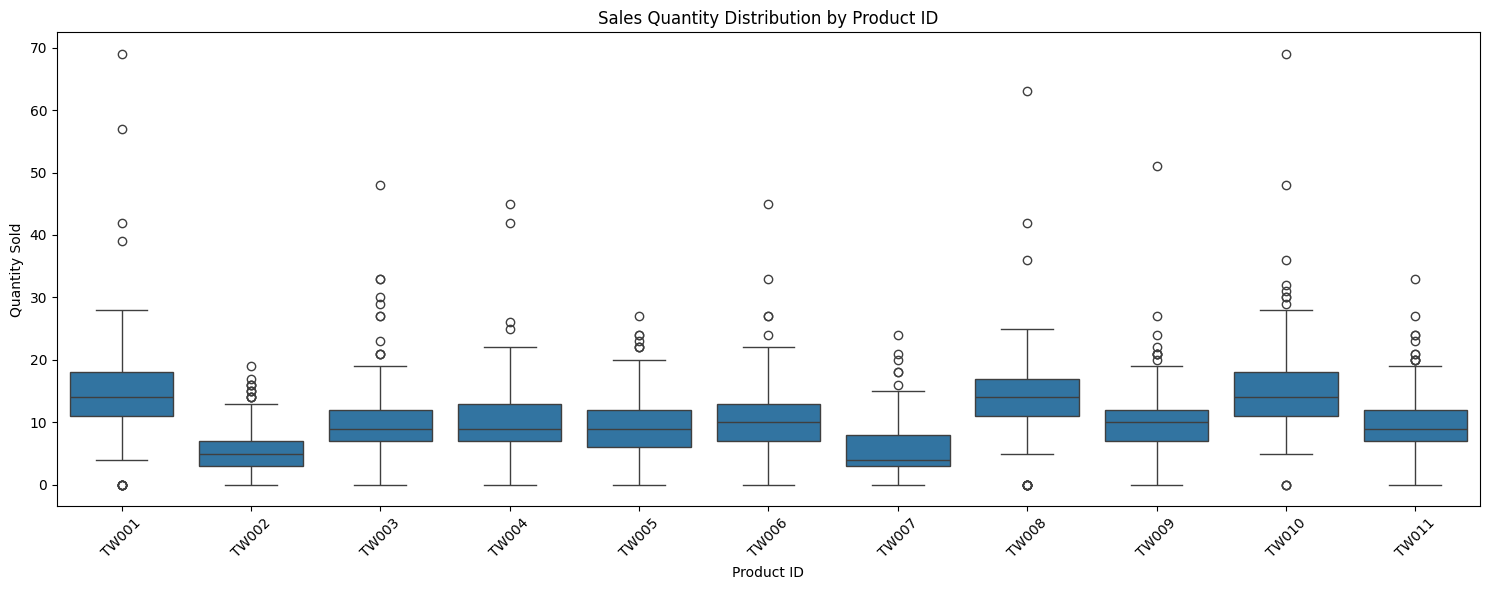

In [31]:
# MISSING VALUES & OUTLIER ANALYSIS
# Outlier tidak otomatis dihapus.

# 1. Missing values
missing_summary = (
    eda_panel.groupby("sku_id")["quantity_clean"]
    .apply(lambda x: x.isna().sum())
    .reset_index(name="missing_quantity")
)

print("MISSING VALUES PER PRODUCT ID")
display(missing_summary)


# 2. Outlier analysis menggunakan metode IQR
valid_sales = eda_panel.dropna(
    subset=["quantity_clean"]
).copy()

q1 = valid_sales["quantity_clean"].quantile(0.25)
q3 = valid_sales["quantity_clean"].quantile(0.75)

iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

valid_sales["is_outlier"] = (
    (valid_sales["quantity_clean"] < lower_bound) |
    (valid_sales["quantity_clean"] > upper_bound)
)

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print(
    "Potential Outliers:",
    valid_sales["is_outlier"].sum()
)


# 3. Boxplot
plt.figure(figsize=(15, 6))

sns.boxplot(
    data=valid_sales,
    x="sku_id",
    y="quantity_clean"
)

plt.title("Sales Quantity Distribution by Product ID")
plt.xlabel("Product ID")
plt.ylabel("Quantity Sold")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [32]:
# Menghitung outlier thresholds tiap SKU sesuai sales distribution.

# Mengambil data dengan quantity valid
outlier_df = valid_sales.copy()

# Menghitung Q1 dan Q3 per SKU
outlier_df["Q1"] = (
    outlier_df.groupby("sku_id")["quantity_clean"]
    .transform(lambda x: x.quantile(0.25))
)

outlier_df["Q3"] = (
    outlier_df.groupby("sku_id")["quantity_clean"]
    .transform(lambda x: x.quantile(0.75))
)

# Menghitung IQR
outlier_df["IQR"] = (
    outlier_df["Q3"] - outlier_df["Q1"]
)

# Menentukan batas outlier
outlier_df["lower_bound"] = (
    outlier_df["Q1"] - 1.5 * outlier_df["IQR"]
)

outlier_df["upper_bound"] = (
    outlier_df["Q3"] + 1.5 * outlier_df["IQR"]
)

# Menandai potential outlier
outlier_df["is_outlier"] = (
    (outlier_df["quantity_clean"] < outlier_df["lower_bound"]) |
    (outlier_df["quantity_clean"] > outlier_df["upper_bound"])
)

# Ringkasan outlier per SKU
outlier_summary = (
    outlier_df.groupby("sku_id")
    .agg(
        total_observations=("quantity_clean", "count"),
        total_outliers=("is_outlier", "sum"),
        lower_bound=("lower_bound", "first"),
        upper_bound=("upper_bound", "first")
    )
    .reset_index()
)

# Menghitung persentase outlier
outlier_summary["outlier_percentage"] = (
    outlier_summary["total_outliers"] /
    outlier_summary["total_observations"] * 100
).round(2)

display(outlier_summary)

,sku_id,total_observations,total_outliers,lower_bound,upper_bound,outlier_percentage
0,TW001,275,11,0.5,28.5,4.00
1,TW002,277,12,-3.0,13.0,4.33
2,TW003,273,11,-0.5,19.5,4.03
3,TW004,271,4,-2.0,22.0,1.48
4,TW005,282,7,-3.0,21.0,2.48
5,TW006,280,5,-2.0,22.0,1.79
6,TW007,280,6,-4.5,15.5,2.14
7,TW008,279,11,2.0,26.0,3.94
8,TW009,275,9,-0.5,19.5,3.27
9,TW010,285,11,0.5,28.5,3.86


In [33]:
# Proporsi kandidat outlier
# Merangkum jumlah dan persentase observasi ekstrem.

# Menghitung jumlah observasi valid
total_valid = len(valid_sales)

# Menghitung jumlah potential outliers
total_outliers = valid_sales["is_outlier"].sum()

# Menghitung persentase outlier
outlier_percentage = (total_outliers / total_valid) * 100

print(f"Total Valid Observations: {total_valid}")
print(f"Total Potential Outliers: {total_outliers}")
print(f"Outlier Percentage: {outlier_percentage:.2f}%")

Total Valid Observations: 3054
Total Potential Outliers: 38
Outlier Percentage: 1.24%


In [34]:
# Menampilkan kembali deret EDA sebelum pengisian.

time_series_data

sku_id,TW001,TW002,TW003,TW004,TW005,TW006,TW007,TW008,TW009,TW010,TW011
order_date,,,,,,,,,,,
2025-01-01,12.0,NaN,5.0,6.0,9.0,8.0,4.0,0.0,7.0,5.0,5.0
2025-01-02,14.0,6.0,5.0,11.0,NaN,9.0,3.0,18.0,5.0,7.0,11.0
2025-01-03,13.0,7.0,9.0,9.0,10.0,7.0,7.0,17.0,10.0,NaN,4.0
2025-01-04,18.0,10.0,14.0,14.0,7.0,9.0,15.0,14.0,10.0,15.0,15.0
2025-01-05,10.0,7.0,15.0,14.0,14.0,10.0,11.0,12.0,13.0,21.0,15.0
...,...,...,...,...,...,...,...,...,...,...,...
2025-10-14,20.0,3.0,5.0,10.0,9.0,11.0,5.0,10.0,12.0,16.0,6.0
2025-10-15,0.0,7.0,3.0,8.0,15.0,8.0,2.0,6.0,14.0,9.0,10.0
2025-10-16,13.0,NaN,7.0,9.0,4.0,4.0,2.0,17.0,6.0,12.0,2.0


In [35]:
# Pemeriksaan Hasil Interpolasi
# Membandingkan jumlah nilai kosong sebelum dan sesudah pengisian untuk grafik.

print("Jumlah NaN sebelum interpolasi:")
print(time_series_data.isna().sum())

print("\nJumlah NaN setelah interpolasi:")
print(time_series_interpolated.isna().sum())

print("\nHasil data setelah diinterpolasi:")
display(time_series_interpolated.head(10))

Jumlah NaN sebelum interpolasi:
sku_id
TW001    16
TW002    14
TW003    18
TW004    20
TW005     9
TW006    11
TW007    11
TW008    12
TW009    16
TW010     6
TW011    14
dtype: int64

Jumlah NaN setelah interpolasi:
sku_id
TW001    0
TW002    0
TW003    0
TW004    0
TW005    0
TW006    0
TW007    0
TW008    0
TW009    0
TW010    0
TW011    0
dtype: int64

Hasil data setelah diinterpolasi:


sku_id,TW001,TW002,TW003,TW004,TW005,TW006,TW007,TW008,TW009,TW010,TW011
order_date,,,,,,,,,,,
2025-01-01,12.0,6.0,5.0,6.0,9.0,8.0,4.0,0.0,7.0,5.0,5.0
2025-01-02,14.0,6.0,5.0,11.0,9.5,9.0,3.0,18.0,5.0,7.0,11.0
2025-01-03,13.0,7.0,9.0,9.0,10.0,7.0,7.0,17.0,10.0,11.0,4.0
2025-01-04,18.0,10.0,14.0,14.0,7.0,9.0,15.0,14.0,10.0,15.0,15.0
2025-01-05,10.0,7.0,15.0,14.0,14.0,10.0,11.0,12.0,13.0,21.0,15.0
2025-01-06,10.0,2.0,11.0,6.0,15.0,12.0,1.0,17.0,10.0,16.0,9.0
2025-01-07,18.0,2.0,8.0,10.0,10.0,0.0,1.0,13.0,7.0,15.0,21.0
2025-01-08,16.0,3.0,8.5,6.0,8.0,3.0,5.0,14.0,11.0,14.0,6.0
2025-01-09,14.0,0.0,9.0,7.0,7.0,7.0,5.0,21.0,11.0,9.0,12.0


In [36]:
# Fungsi audit tanggal tidak lengkap
# Menghitung banyaknya SKU tanpa kuantitas tercatat pada setiap tanggal.

def check_incomplete_dates(dataframe):
    # Ringkas tanggal dengan sedikitnya satu total produk yang belum diketahui.
    incomplete = dataframe.loc[dataframe["quantity_clean"].isna()]
    display(
        incomplete.groupby("order_date")["sku_id"].nunique()
        .rename("products_without_total").to_frame()
    )

In [37]:
# Jalankan audit kelengkapan EDA
# Menampilkan tanggal yang masih memiliki aktual kosong pada panel asli.

check_incomplete_dates(eda_panel)

,products_without_total
order_date,
2025-01-01,1
2025-01-02,1
2025-01-03,1
2025-01-07,1
2025-01-08,2
...,...
2025-09-25,1
2025-09-28,1
2025-10-03,4


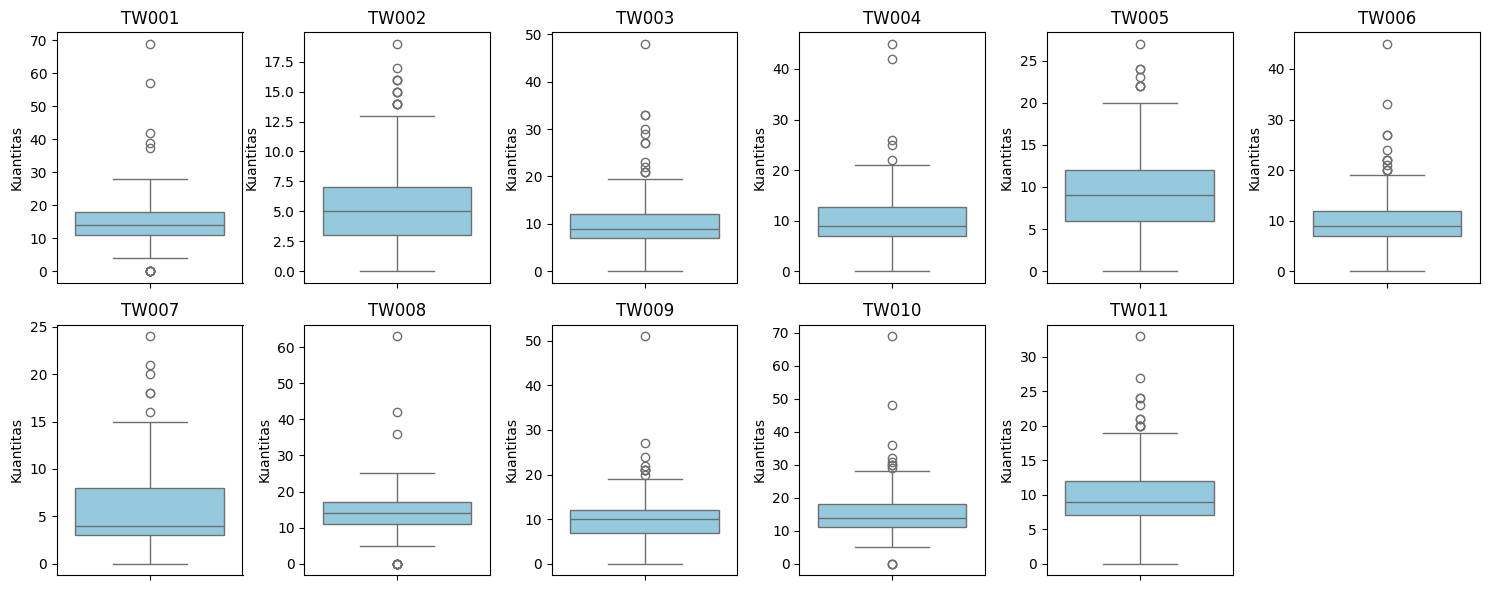

In [38]:
# Boxplot per SKU
# Menampilkan sebaran nilai dari deret EDA terinterpolasi untuk tiap SKU.

product_columns = time_series_interpolated.columns
fig, axes = plt.subplots(2, (len(product_columns) + 1) // 2, figsize=(15, 6))
for ax, product_id in zip(axes.flat, product_columns):
    sns.boxplot(y=time_series_interpolated[product_id], color="skyblue", ax=ax)
    ax.set_title(product_id)
    ax.set_ylabel("Kuantitas")
for ax in list(axes.flat)[len(product_columns):]:
    ax.set_visible(False)
fig.tight_layout()
plt.show()

## Interpretasi Outlier

IQR global dan IQR per produk menggunakan ambang masing-masing. Persentase outlier paling besar di 4,33% dan rata-rata adalah 1,24%.
Penjualan tinggi tetap dipertahankan. IQR dipakai untuk eksplorasi, tanpa mengubah target atau fitur model.

# Data Validation

In [40]:
# Pemeriksaan panel
# Memeriksa keunikan kunci, kuantitas nonnegatif, dan struktur kalender.

# 1. Pastikan setiap pasangan tanggal dan SKU hanya muncul sekali
assert not panel.duplicated(sku_day_key).any()
# 2. Pastikan kuantitas yang tersedia tidak negatif
assert panel["quantity_clean"].dropna().ge(0).all()
assert panel.groupby("sku_id")["order_date"].nunique().eq(len(dates)).all()
known_skus = set(eda_panel.loc[eda_panel["quality_issue"].ne("missing_sku_day"), "sku_id"])

assert known_skus == set(catalog["sku_id"])

# 3. Periksa jumlah SKU forecast dan jumlah produk stok
assert catalog["sku_id"].nunique() == 11
assert catalog["stock_product_id"].nunique() == 10

# 4. Pastikan produk stok brownies hanya mencakup TW001 dan TW002
assert set(catalog.loc[catalog["stock_product_id"].eq("TW001"), "sku_id"]) == {"TW001", "TW002"}

print(f"Panel: {len(panel)} baris, {len(dates)} tanggal, {len(catalog)} SKU")

Panel: 4015 baris, 365 tanggal, 11 SKU


# Feature Engineering

In [41]:
# Membentuk fitur kalender, lag, dan rolling dari informasi yang tersedia saat forecast.

# Data aktual H−2 diasumsikan lengkap saat forecast dibuat pada akhir hari.
def build_h2_features(daily_panel):
    data = daily_panel.sort_values(["sku_id", "order_date"]).copy()
    d = data["order_date"].dt
    data["forecast_origin"] = data["order_date"] - pd.Timedelta(days=HORIZON)

    data["day_of_week"] = d.dayofweek
    data["day_of_month"] = d.day
    data["month"] = d.month
    data["week_of_year"] = d.isocalendar().week.astype(int)
    data["is_weekend"] = (d.dayofweek >= 5).astype(int)
    data["is_month_start"] = d.is_month_start.astype(int)
    data["is_month_end"] = d.is_month_end.astype(int)

    sales = data.groupby("sku_id")["quantity_clean"]
    for lag in (HORIZON, 3, 7, 14):
        data[f"lag_{lag}"] = sales.shift(lag)

    for window in (7, 14):
        data[f"rolling_mean_{window}"] = sales.transform(
            lambda s: s.shift(HORIZON).rolling(window, min_periods=3).mean()
        )
        data[f"history_count_{window}"] = sales.transform(
            lambda s: s.shift(HORIZON).rolling(window, min_periods=1).count()
        )
    data["rolling_std_7"] = sales.transform(
        lambda s: s.shift(HORIZON).rolling(7, min_periods=3).std()
    )
    return data

feature_panel = build_h2_features(panel)
display(feature_panel[["order_date", "forecast_origin", "sku_id", "lag_2"]].head(20))

,order_date,forecast_origin,sku_id,lag_2
0,2025-01-01,2024-12-30,TW001,NaN
1,2025-01-02,2024-12-31,TW001,NaN
2,2025-01-03,2025-01-01,TW001,12.0
3,2025-01-04,2025-01-02,TW001,14.0
4,2025-01-05,2025-01-03,TW001,13.0
5,2025-01-06,2025-01-04,TW001,18.0
6,2025-01-07,2025-01-05,TW001,10.0
7,2025-01-08,2025-01-06,TW001,10.0
8,2025-01-09,2025-01-07,TW001,18.0
9,2025-01-10,2025-01-08,TW001,NaN


In [42]:
# Menetapkan masukan model dan kuantitas tercatat sebagai target.

# Gunakan ID SKU dan fitur yang tersedia pada H−2.
features = [
    "sku_id",
    "day_of_week",
    "day_of_month",
    "month",
    "week_of_year",
    "is_weekend",
    "is_month_start",
    "is_month_end",
    "lag_2",
    "lag_3",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_14",
    "rolling_std_7",
    "history_count_7",
    "history_count_14",
]
target = "quantity_clean"
print(f"Jumlah fitur: {len(features)}")

Jumlah fitur: 17


In [43]:
# Memakai label valid sampai batas forecast pertama dan mempertahankan seluruh kalender test.

# Tanggal training tetap mencakup 80% kalender.
train_calendar = feature_panel.loc[feature_panel["order_date"].lt(split_date)].copy()

# Aktual pada split_date − 1 belum tersedia saat forecast pertama diterbitkan.
train = train_calendar.loc[
    train_calendar["order_date"].le(first_origin) & train_calendar[target].notna()
].copy()
test = feature_panel.loc[feature_panel["order_date"].ge(split_date)].copy()

if train.empty or test.empty or not test[target].notna().any():
    raise ValueError("Training perlu target valid dan testing perlu aktual untuk evaluasi.")

print(f"Baris training kalender: {len(train_calendar)}")
print(f"Label untuk fit awal: {len(train)}")
print(f"Baris testing untuk diprediksi: {len(test)}")
print(f"Target aktual testing yang valid: {test[target].count()}")

Baris training kalender: 3212
Label untuk fit awal: 3054
Baris testing untuk diprediksi: 803
Target aktual testing yang valid: 773


In [44]:
# Uji batas informasi H−2
# Memeriksa bahwa perubahan data setelah tanggal forecast tidak mengubah fitur yang dipakai.

# Periksa informasi yang dipakai di awal dan pertengahan periode uji.
assert train["order_date"].max() <= test["forecast_origin"].min() == first_origin
assert test["order_date"].nunique() == len(dates) - split_idx
assert (test["order_date"] - test["forecast_origin"]).eq(pd.Timedelta(days=2)).all()

test_dates = test["order_date"].drop_duplicates()
for target_date in (split_date, test_dates.iloc[len(test_dates) // 2]):
    cutoff = target_date - pd.Timedelta(days=HORIZON)
    changed = panel.copy()
    changed.loc[changed["order_date"].gt(cutoff), target] = 999_999.0
    recomputed = build_h2_features(changed)
    original_features = test.loc[test["order_date"].eq(target_date), features]
    changed_features = recomputed.loc[recomputed["order_date"].eq(target_date), features]
    pd.testing.assert_frame_equal(original_features, changed_features)

print("Pemeriksaan batas H−2 lulus.")

Pemeriksaan batas H−2 lulus.


In [45]:
# Praproses fitur model Random Forest, XGBoost, dan MLP
# Mengodekan SKU, mengisi fitur numerik kosong dengan median, dan menskalakan masukan MLP.

categorical_features = ["sku_id"]
numerical_features = [col for col in features if col not in categorical_features]
categorical_transformer = OneHotEncoder(handle_unknown="ignore")

preprocessor_tree = ColumnTransformer([
    ("sku_id", categorical_transformer, categorical_features),
    ("num", SimpleImputer(strategy="median"), numerical_features),
])
preprocessor_mlp = ColumnTransformer([
    ("sku_id", categorical_transformer, categorical_features),
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), numerical_features),
])

# Model Training

In [47]:
# Konfigurasi XGBoost
# Menetapkan parameter XGBoost untuk pipeline model pohon.

# Konfigurasi XGBoost H−2 untuk dipasang pada pipeline
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.04,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    n_jobs=2,
    random_state=SEED,
)

In [48]:
# Tuning XGBoost dengan validasi kronologis H−2

# 1. Siapkan periode validasi dan konfigurasi pembanding
tuning_starts = pd.to_datetime(["2025-07-01", "2025-08-01", "2025-09-01"])
tuning_candidates = [
    {}, # Kandidat 0 memakai konfigurasi asli dari Cell sebelumnya
    *[
        {
            "max_depth": depth,
            "min_child_weight": child_weight,
            "learning_rate": rate,
            "n_estimators": trees,
        }
        for depth in (2, 3)
        for child_weight in (1, 5)
        for rate, trees in ((0.04, 300), (0.08, 150))
    ],
]

# 2. Siapkan train dan validasi memakai aktual tercatat
tuning_folds = []
for start in tuning_starts:
    end = start + pd.Timedelta(days=27)
    cutoff = start - pd.Timedelta(days=HORIZON)

    if end >= split_date:
        raise ValueError("Periode tuning masuk ke test akhir.")

    fold_train = feature_panel.loc[
        feature_panel["order_date"].le(cutoff)
    ].dropna(subset=[target])

    fold_valid = feature_panel.loc[
        feature_panel["order_date"].between(start, end)
    ].dropna(subset=[target])

    if fold_train.empty or fold_valid.empty:
        raise ValueError(f"Data tuning tidak cukup untuk {start:%Y-%m}.")

    tuning_folds.append((fold_train, fold_valid))

# 3. Ukur error setiap konfigurasi pada seluruh periode
tuning_rows = []
for candidate_id, params in enumerate(tuning_candidates):
    total_error = 0.0
    total_actuals = 0

    for fold_train, fold_valid in tuning_folds:
        pipeline = Pipeline([
            ("preprocess", clone(preprocessor_tree)),
            ("model", clone(xgb_model).set_params(**params)),
        ])
        pipeline.fit(fold_train[features], fold_train[target])
        forecast = np.maximum(0, pipeline.predict(fold_valid[features]))

        total_error += np.abs(fold_valid[target].to_numpy() - forecast).sum()
        total_actuals += len(fold_valid)

    tuning_rows.append({
        "kandidat": candidate_id,
        "parameter": params,
        "MAE validasi": total_error / total_actuals,
    })

# 4. Siapkan konfigurasi terbaik untuk pipeline di Cell 51
xgb_tuning_results = (
    pd.DataFrame(tuning_rows)
    .sort_values(["MAE validasi", "kandidat"])
    .reset_index(drop=True)
)

best_xgb_params = xgb_tuning_results.at[0, "parameter"]
xgb_model = clone(xgb_model).set_params(**best_xgb_params)

display(xgb_tuning_results.round(3))

,kandidat,parameter,MAE validasi
0,2,"{'max_depth': 2, 'min_child_weight': 1, 'learn...",3.222
1,4,"{'max_depth': 2, 'min_child_weight': 5, 'learn...",3.224
2,1,"{'max_depth': 2, 'min_child_weight': 1, 'learn...",3.242
3,3,"{'max_depth': 2, 'min_child_weight': 5, 'learn...",3.245
4,7,"{'max_depth': 3, 'min_child_weight': 5, 'learn...",3.302
5,8,"{'max_depth': 3, 'min_child_weight': 5, 'learn...",3.318
6,5,"{'max_depth': 3, 'min_child_weight': 1, 'learn...",3.346
7,6,"{'max_depth': 3, 'min_child_weight': 1, 'learn...",3.381
8,0,{},3.414


In [49]:
# MACHINE LEARNING MODEL TRAINING

# Latih Random Forest, XGBoost, dan MLP
# Membuat pipeline dan melatih tiga model untuk prediksi test.

models = {
    "Random Forest": Pipeline([
        ("preprocess", clone(preprocessor_tree)),
        ("model", RandomForestRegressor(
            n_estimators=250,
            max_depth=12,
            min_samples_leaf=3,
            random_state=SEED,
            n_jobs=-1
        ))
    ]),

    "XGBoost": Pipeline([
        ("preprocess", clone(preprocessor_tree)),
        ("model", xgb_model)
    ]),

    "MLP": Pipeline([
        ("preprocess", clone(preprocessor_mlp)),
        ("model", MLPRegressor(
            hidden_layer_sizes=(48, 24),
            alpha=1.0,
            max_iter=1000,
            tol=1e-3,
            early_stopping=False,
            random_state=SEED
        ))
    ])
}

X_train = train[features]
y_train = train[target]

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    print(f"{name}: Training Completed")

Random Forest: Training Completed
XGBoost: Training Completed
MLP: Training Completed


# Validasi Kronologis Model untuk H-2

In [50]:
# VALIDASI KRONOLOGIS H−2
# Validasi tiga periode
# Melatih ulang model per periode dan membandingkan error H−2 terhadap aktual tercatat.

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.statespace.sarimax import SARIMAX

validation_starts = pd.to_datetime([
    "2025-07-01",
    "2025-08-01",
    "2025-09-01",
])
validation_days = 28
one_day = pd.Timedelta(days=1)
horizon_delta = pd.Timedelta(days=HORIZON)

# Kalender harian lengkap. Aktual kosong tetap NaN.
validation_daily_sales = (
    feature_panel.pivot(
        index="order_date",
        columns="sku_id",
        values=target,
    )
    .sort_index()
    .asfreq("D")
)

validation_rows = []

for start in validation_starts:
    end = start + pd.Timedelta(days=validation_days - 1)
    first_validation_origin = start - horizon_delta

    if end >= split_date:
        raise ValueError(
            f"Periode validasi {start:%Y-%m-%d} s.d. {end:%Y-%m-%d} "
            "masuk ke data testing akhir."
        )

    fold_train = feature_panel.loc[
        feature_panel["order_date"].le(first_validation_origin)
    ].dropna(subset=[target])

    fold_valid = (
        feature_panel.loc[feature_panel["order_date"].between(start, end)]
        .dropna(subset=[target])
        .sort_values(["sku_id", "order_date"])
        .copy()
    )

    if fold_train.empty or fold_valid.empty:
        raise ValueError(f"Data tidak cukup untuk validasi mulai {start:%Y-%m-%d}.")

    assert fold_train["order_date"].max() <= fold_valid["forecast_origin"].min()
    assert (
        fold_valid["order_date"] - fold_valid["forecast_origin"]
    ).eq(horizon_delta).all()

    # RF, XGBoost, dan MLP. Clone agar fit validasi memakai pipeline baru.
    training_mae = {}
    for name, estimator in models.items():
        fold_model = clone(estimator).fit(
            fold_train[features],
            fold_train[target],
        )

        train_pred = np.maximum(0, fold_model.predict(fold_train[features]))
        fold_valid[name] = np.maximum(0, fold_model.predict(fold_valid[features]))
        training_mae[name] = mean_absolute_error(fold_train[target], train_pred)

    # SARIMA. Fit parameter sekali per SKU, lalu perbarui state hingga H−2.
    fold_valid["SARIMA"] = np.nan

    for sku_id, sku_valid in fold_valid.groupby("sku_id", sort=False):
        sales = validation_daily_sales[sku_id]
        state = SARIMAX(
            sales.loc[:first_validation_origin],
            order=(1, 1, 1),
            seasonal_order=(1, 1, 1, 7),
        ).fit(disp=False, maxiter=200)

        if not state.mle_retvals["converged"]:
            print(f"SARIMA belum konvergen: {sku_id}, validasi {start:%Y-%m}")

        state_date = first_validation_origin

        for idx, row in sku_valid.iterrows():
            origin = row["forecast_origin"]

            if origin > state_date:
                state = state.extend(sales.loc[state_date + one_day:origin])
                state_date = origin

            forecast = state.forecast(steps=HORIZON)
            assert forecast.index[-1] == row["order_date"]
            fold_valid.at[idx, "SARIMA"] = max(0.0, float(forecast.iloc[-1]))

    # Bandingkan baseline H−7 dan keempat model pada baris yang sama.
    matched = fold_valid.dropna(subset=["lag_7"])
    baseline_mae = (
        mean_absolute_error(matched[target], matched["lag_7"])
        if len(matched) else np.nan
    )

    for name in ["SARIMA", *models]:
        valid_mae = mean_absolute_error(fold_valid[target], fold_valid[name])
        train_mae = training_mae.get(name, np.nan)

        validation_rows.append({
            "Periode validasi": f"{start:%d/%m/%Y}–{end:%d/%m/%Y}",
            "Model": name,
            "N validasi": len(fold_valid),
            "MAE training": train_mae,
            "MAE validasi": valid_mae,
            "Selisih MAE validasi − training": valid_mae - train_mae,
            "N perbandingan H−7": len(matched),
            "MAE model pada baris H−7": (
                mean_absolute_error(matched[target], matched[name])
                if len(matched) else np.nan
            ),
            "MAE baseline H−7": baseline_mae,
        })

validation_results = pd.DataFrame(validation_rows)
display(
    validation_results
    .sort_values(["Periode validasi", "MAE validasi"])
    .round(3)
)

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


,Periode validasi,Model,N validasi,MAE training,MAE validasi,Selisih MAE validasi − training,N perbandingan H−7,MAE model pada baris H−7,MAE baseline H−7
2,01/07/2025–28/07/2025,XGBoost,294,2.851,3.226,0.375,283,3.261,4.311
0,01/07/2025–28/07/2025,SARIMA,294,NaN,3.272,NaN,283,3.305,4.311
1,01/07/2025–28/07/2025,Random Forest,294,1.987,3.279,1.292,283,3.307,4.311
3,01/07/2025–28/07/2025,MLP,294,1.765,4.664,2.899,283,4.660,4.311
4,01/08/2025–28/08/2025,SARIMA,298,NaN,3.286,NaN,285,3.126,4.789
6,01/08/2025–28/08/2025,XGBoost,298,2.897,3.445,0.547,285,3.298,4.789
5,01/08/2025–28/08/2025,Random Forest,298,2.043,3.716,1.673,285,3.576,4.789
7,01/08/2025–28/08/2025,MLP,298,2.467,3.934,1.467,285,3.822,4.789
10,01/09/2025–28/09/2025,XGBoost,291,2.940,2.990,0.050,276,3.000,4.094
9,01/09/2025–28/09/2025,Random Forest,291,2.125,3.093,0.968,276,3.110,4.094


In [51]:
# Model Ranking & Choose Selected Model
# Mengurutkan MAE gabungan berbobot jumlah observasi dan menetapkan selected_model.

validation_ranking = (
    validation_results
    .assign(
        total_absolute_error=lambda df: df["MAE validasi"] * df["N validasi"]
    )
    .groupby("Model", as_index=False)
    .agg(
        total_absolute_error=("total_absolute_error", "sum"),
        n_observations=("N validasi", "sum"),
    )
    .assign(
        mae_validasi=lambda df: df["total_absolute_error"] / df["n_observations"]
    )
    .sort_values("mae_validasi", ignore_index=True)
)

# Model dengan MAE validasi H−2 terendah
validation_winner = validation_ranking.loc[0, "Model"]

# Keputusan proyek untuk demo Tewiwi
deployment_model = "XGBoost"

display(validation_ranking[["Model", "n_observations", "mae_validasi"]].round(4))
print(f"MAE validasi H−2 terendah: {validation_winner}")
print(f"Model untuk demo Tewiwi: {deployment_model}")

,Model,n_observations,mae_validasi
0,SARIMA,883,3.2183
1,XGBoost,883,3.2221
2,Random Forest,883,3.3651
3,MLP,883,4.2278


MAE validasi H−2 terendah: SARIMA
Model untuk demo Tewiwi: XGBoost


In [52]:
# Prediksi test dan baseline
# Mengisi prediksi tiga model ML dan pembanding Seasonal Naive dari aktual H−7.

predictions = test[["order_date", "forecast_origin", "sku_id", target]].copy()
for name, pipeline in models.items():
    predictions[name] = np.maximum(0, pipeline.predict(test[features]))

predictions["Seasonal Naive"] = test["lag_7"]
display(predictions.head(20))

,order_date,forecast_origin,sku_id,quantity_clean,Random Forest,XGBoost,MLP,Seasonal Naive
292,2025-10-20,2025-10-18,TW001,8.0,11.916226,12.382377,15.672403,14.0
293,2025-10-21,2025-10-19,TW001,9.0,12.234283,12.196095,12.280168,20.0
294,2025-10-22,2025-10-20,TW001,14.0,10.267561,12.868970,11.174787,0.0
295,2025-10-23,2025-10-21,TW001,15.0,12.095638,12.732469,14.594484,13.0
296,2025-10-24,2025-10-22,TW001,12.0,12.954349,14.726478,12.373326,15.0
297,2025-10-25,2025-10-23,TW001,20.0,19.343409,17.871756,16.302077,20.0
298,2025-10-26,2025-10-24,TW001,18.0,19.367192,18.364063,19.075348,18.0
299,2025-10-27,2025-10-25,TW001,15.0,11.840251,14.172594,12.683596,8.0
300,2025-10-28,2025-10-26,TW001,17.0,12.166913,14.335042,7.475676,9.0
301,2025-10-29,2025-10-27,TW001,11.0,10.550596,12.411102,10.382242,14.0


# SARIMA Model (H−2 per ID Produk)

In [53]:
# Prediksi test SARIMA
# Melatih SARIMA per SKU dan memperbarui state dengan informasi sampai tanggal forecast.

# Fit parameter SARIMA per SKU sekali. Perbarui state dengan aktual hingga H−2.
daily_sales = (
    panel.pivot(index="order_date", columns="sku_id", values=target)
    .sort_index()
    .asfreq("D")
)
predictions["SARIMA"] = np.nan
sarima_diagnostics = []

for sku_id, product_test in test.groupby("sku_id", sort=False):
    series = daily_sales[sku_id]
    initial_history = series.loc[:first_origin]
    if initial_history.notna().sum() < 14:
        raise ValueError(f"Riwayat valid terlalu pendek untuk SARIMA pada {sku_id}.")

    fitted = SARIMAX(
        initial_history,
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 7),
    ).fit(disp=False, maxiter=200)
    sarima_diagnostics.append({
        "sku_id": sku_id,
        "converged": bool(fitted.mle_retvals["converged"]),
    })

    state = fitted
    state_date = first_origin
    for idx, row in product_test.sort_values("order_date").iterrows():
        origin = row["forecast_origin"]
        if origin > state_date:
            new_observations = series.loc[
                state_date + pd.Timedelta(days=1):origin
            ]
            # Hari tanpa aktual tetap NaN agar jarak waktunya terjaga.
            state = state.extend(new_observations)
            state_date = origin

        forecast = state.forecast(steps=HORIZON)
        assert forecast.index[-1] == row["order_date"]
        predictions.at[idx, "SARIMA"] = max(float(forecast.iloc[-1]), 0.0)

display(pd.DataFrame(sarima_diagnostics))

,sku_id,converged
0,TW001,True
1,TW002,True
2,TW003,True
3,TW004,True
4,TW005,True
5,TW006,True
6,TW007,True
7,TW008,True
8,TW009,True
9,TW010,True


In [54]:
# Evaluasi test akhir
# Menghitung MAE dan RMSE pada aktual yang sama, termasuk hasil per SKU, baseline, dan agregasi stok.

# Metrik empat model pada himpunan aktual yang sama.
model_names = ["SARIMA", *models]
if not np.isfinite(predictions[model_names].to_numpy()).all():
    raise ValueError("Ada hasil prediksi model yang hilang atau tidak berhingga.")

scored = predictions.dropna(subset=[target]).copy()
coverage = (
    predictions.groupby("sku_id")[target]
    .agg(target_valid="count", hari_testing="size")
    .reset_index()
)

def compare_models(frame, names):
    actual = frame[target]
    return pd.DataFrame([
        {
            "Model": name,
            "N": len(frame),
            "MAE": mean_absolute_error(actual, frame[name]),
            "RMSE": np.sqrt(mean_squared_error(actual, frame[name])),
        }
        for name in names
    ]).sort_values("MAE", ignore_index=True)

metrics = compare_models(scored, model_names)
metrics_by_product = pd.concat([
    compare_models(group, model_names).assign(sku_id=sku_id)
    for sku_id, group in scored.groupby("sku_id")
], ignore_index=True).merge(
    catalog[["sku_id", "product_name", "variant"]],
    on="sku_id",
    validate="many_to_one",
)

print("Cakupan aktual testing")
display(coverage)
print("MAE dan RMSE gabungan")
display(metrics)
print("MAE dan RMSE per SKU")
display(metrics_by_product[["sku_id", "product_name", "variant", "Model", "N", "MAE", "RMSE"]])

baseline_subset = scored.dropna(subset=["Seasonal Naive"])
if not baseline_subset.empty:
    print("Perbandingan dengan baseline pada baris yang sama-sama memiliki aktual H−7")
    display(compare_models(baseline_subset, [*model_names, "Seasonal Naive"]))

# Nilai juga kebutuhan kotor stok setelah menjumlahkan prediksi SKU.
with_stock_id = predictions.merge(
    catalog[["sku_id", "stock_product_id"]], on="sku_id", validate="many_to_one"
)
stock_groups = with_stock_id.groupby(["order_date", "forecast_origin", "stock_product_id"])
stock_backtest = stock_groups[model_names].sum()
# Aktual stok lengkap hanya jika semua SKU dalam grup memiliki aktual.
stock_backtest[target] = stock_groups[target].sum(min_count=1).where(
    stock_groups[target].count().eq(stock_groups.size())
)
stock_backtest = stock_backtest.reset_index()
stock_scored = stock_backtest.dropna(subset=[target])
stock_metrics = compare_models(stock_scored, model_names)
print("Evaluasi kebutuhan stok, setelah agregasi per produk")
display(stock_metrics)
print("Evaluasi stok khusus Espresso Fudgy Brownies")
display(compare_models(stock_scored.loc[stock_scored["stock_product_id"].eq("TW001")], model_names))

Cakupan aktual testing


,sku_id,target_valid,hari_testing
0,TW001,66,73
1,TW002,70,73
2,TW003,72,73
3,TW004,71,73
4,TW005,72,73
5,TW006,70,73
6,TW007,72,73
7,TW008,72,73
8,TW009,69,73
9,TW010,69,73


MAE dan RMSE gabungan


,Model,N,MAE,RMSE
0,XGBoost,773,3.209766,5.077688
1,SARIMA,773,3.211172,5.090903
2,Random Forest,773,3.325943,5.183979
3,MLP,773,4.226906,6.230991


MAE dan RMSE per SKU


,sku_id,product_name,variant,Model,N,MAE,RMSE
0,TW001,Espresso Fudgy Brownies,Small,XGBoost,66,4.226139,5.956330
1,TW001,Espresso Fudgy Brownies,Small,Random Forest,66,4.292914,6.047337
2,TW001,Espresso Fudgy Brownies,Small,SARIMA,66,4.304096,5.898695
3,TW001,Espresso Fudgy Brownies,Small,MLP,66,5.445163,7.506934
4,TW002,Espresso Fudgy Brownies,Large,SARIMA,70,2.076399,2.481148
5,TW002,Espresso Fudgy Brownies,Large,XGBoost,70,2.232544,2.664262
6,TW002,Espresso Fudgy Brownies,Large,Random Forest,70,2.528217,3.021790
7,TW002,Espresso Fudgy Brownies,Large,MLP,70,2.762847,3.477199
8,TW003,Blueberry Cheese Crumble,Standard,SARIMA,72,3.371313,5.209611
9,TW003,Blueberry Cheese Crumble,Standard,Random Forest,72,3.426476,5.330492


... (2 outputs left out)

Evaluasi kebutuhan stok, setelah agregasi per produk


,Model,N,MAE,RMSE
0,XGBoost,700,3.313124,5.257032
1,SARIMA,700,3.321199,5.266250
2,Random Forest,700,3.429456,5.359887
3,MLP,700,4.441758,6.513191


Evaluasi stok khusus Espresso Fudgy Brownies


,Model,N,MAE,RMSE
0,SARIMA,63,4.317803,5.782672
1,XGBoost,63,4.337163,5.981047
2,Random Forest,63,4.602738,6.158449
3,MLP,63,6.263690,8.212434


In [55]:
# Evaluasi demand harian untuk pesanan yang masuk pada Selasa dan Jumat
# Filter berdasarkan order_date, yaitu tanggal pelanggan memesan.
# MAE dan RMSE di bawah dihitung dari pasangan tanggal pemesanan–SKU.

delivery_weekdays = (1, 4)  # Senin = 0

slot_predictions = predictions.loc[
    predictions["order_date"].dt.dayofweek.isin(delivery_weekdays)
].copy()
slot_scored = slot_predictions.dropna(subset=[target])
slot_matched = slot_scored.dropna(subset=["Seasonal Naive"])

if slot_matched.empty:
    raise ValueError(
        "Tidak ada baris pesanan Selasa/Jumat dengan aktual dan baseline H−7 lengkap."
    )

print(f"Tanggal pemesanan yang diuji: {slot_predictions['order_date'].nunique()}")
print(f"Aktual harian tersedia: {len(slot_scored)} dari {len(slot_predictions)}")
print(f"Baris tanggal pemesanan–SKU untuk pembandingan H−7: {len(slot_matched)}")

display(
    compare_models(
        slot_matched,
        [deployment_model, "SARIMA", "Seasonal Naive"],
    ).round(4)
)

slot_stock_scored = stock_scored.loc[
    stock_scored["order_date"].dt.dayofweek.isin(delivery_weekdays)
]
if not slot_stock_scored.empty:
    print("MAE dan RMSE per produk stok per hari pemesanan (Selasa/Jumat)")
    display(
        compare_models(
            slot_stock_scored,
            [deployment_model, "SARIMA"],
        ).round(4)
    )

Tanggal pemesanan yang diuji: 21
Aktual harian tersedia: 221 dari 231
Baris tanggal pemesanan–SKU untuk pembandingan H−7: 213


,Model,N,MAE,RMSE
0,XGBoost,213,2.8313,4.7421
1,SARIMA,213,2.8703,4.7447
2,Seasonal Naive,213,4.2254,6.6077


MAE dan RMSE per produk stok per hari pemesanan (Selasa/Jumat)


,Model,N,MAE,RMSE
0,XGBoost,200,2.9791,4.8893
1,SARIMA,200,3.0248,4.8918


In [56]:
# Ringkasan pemilihan model dan hasil test H−2

    # 1. Ambil MAE validasi yang menjadi dasar pemilihan model
ringkasan_model = (
    validation_ranking[["Model", "mae_validasi"]]
    .rename(columns={"mae_validasi": "MAE validasi"})
    # 2. Tambahkan MAE test untuk prediksi di tingkat SKU
    .merge(
        metrics[["Model", "MAE"]].rename(columns={"MAE": "MAE test per SKU"}),
        on="Model",
        validate="one_to_one",
    )
    # 3. Tambahkan MAE test setelah prediksi SKU digabung per produk stok
    .merge(
        stock_metrics[["Model", "MAE"]].rename(
            columns={"MAE": "MAE test stok per produk"}
        ),
        on="Model",
        validate="one_to_one",
    )
    # 4. Urutkan tabel berdasarkan kriteria pemilihan model
    .sort_values("MAE validasi")
    .reset_index(drop=True)
)

ringkasan_model["Model demo"] = ringkasan_model["Model"].eq(deployment_model)

display(ringkasan_model.round(4))
print(f"MAE validasi H−2 terendah: {validation_winner}")
print(f"Model untuk demo Tewiwi: {deployment_model}")

,Model,MAE validasi,MAE test per SKU,MAE test stok per produk,Model demo
0,SARIMA,3.2183,3.2112,3.3212,False
1,XGBoost,3.2221,3.2098,3.3131,True
2,Random Forest,3.3651,3.3259,3.4295,False
3,MLP,4.2278,4.2269,4.4418,False


MAE validasi H−2 terendah: SARIMA
Model untuk demo Tewiwi: XGBoost


In [57]:
# Aturan alokasi order harian ke slot pengiriman

# 1. Tetapkan jadwal pengiriman dan asumsi cutoff demo
DELIVERY_WEEKDAYS = (1, 4)  # Selasa dan Jumat, dengan Senin = 0
SIMULATED_ORDER_CUTOFF_DAYS = 1

def build_slot_calendar(first_order_date, last_order_date):
    """Buat daftar slot dan rentang tanggal order yang masuk ke tiap slot."""
    # 2. Sertakan slot sebelum dan sesudah periode test agar batasnya lengkap
    calendar = pd.date_range(
        first_order_date - pd.Timedelta(days=7),
        last_order_date + pd.Timedelta(days=7 + SIMULATED_ORDER_CUTOFF_DAYS),
        freq="D",
    )
    delivery_dates = calendar[calendar.dayofweek.isin(DELIVERY_WEEKDAYS)]
    slots = pd.DataFrame({"delivery_date": delivery_dates})

    # 3. Tetapkan tanggal order terakhir dan tanggal mulai jendela tiap slot
    slots["order_window_end"] = (
        slots["delivery_date"]
        - pd.Timedelta(days=SIMULATED_ORDER_CUTOFF_DAYS)
    )
    slots["order_window_start"] = (
        slots["order_window_end"].shift(1) + pd.Timedelta(days=1)
    )

    # 4. Tetapkan tanggal estimasi kebutuhan produksi diterbitkan
    slots["slot_forecast_origin"] = (
        slots["delivery_date"] - pd.Timedelta(days=HORIZON)
    )
    return slots.dropna(subset=["order_window_start"]).reset_index(drop=True)


# 5. Pakai tanggal dari prediksi test harian yang sudah tersedia
first_test_order = predictions["order_date"].min()
last_test_order = predictions["order_date"].max()

slot_calendar = build_slot_calendar(first_test_order, last_test_order)
display(slot_calendar.head())

,delivery_date,order_window_end,order_window_start,slot_forecast_origin
0,2025-10-17,2025-10-16,2025-10-14,2025-10-15
1,2025-10-21,2025-10-20,2025-10-17,2025-10-19
2,2025-10-24,2025-10-23,2025-10-21,2025-10-22
3,2025-10-28,2025-10-27,2025-10-24,2025-10-26
4,2025-10-31,2025-10-30,2025-10-28,2025-10-29


In [58]:
# Backtest estimasi kebutuhan per slot dan SKU

# 1. Ambil slot yang seluruh jendela order-nya tercakup dalam test 20%
complete_test_slots = slot_calendar.loc[
    slot_calendar["order_window_start"].ge(first_test_order)
    & slot_calendar["order_window_end"].le(last_test_order)
].copy()

if complete_test_slots.empty:
    raise ValueError("Periode test belum mencakup satu jendela slot lengkap.")

slot_models = [deployment_model, "SARIMA", "Seasonal Naive"]
daily_test = predictions.sort_values("order_date").copy()

if daily_test.duplicated(["order_date", "sku_id"]).any():
    raise ValueError("Ada prediksi ganda untuk pasangan tanggal dan SKU.")

# 2. Bentuk daftar tanggal order yang dialokasikan ke tiap slot
slot_order_days = complete_test_slots.assign(
    order_date=[
        pd.date_range(start, end, freq="D")
        for start, end in zip(
            complete_test_slots["order_window_start"],
            complete_test_slots["order_window_end"],
        )
    ]
).explode("order_date", ignore_index=True)

slot_daily = daily_test.merge(
    slot_order_days[["order_date", "delivery_date", "slot_forecast_origin"]],
    on="order_date",
    how="inner",
    validate="many_to_one",
)

# 3. Periksa cakupan kalender dan batas informasi H−2
expected_rows = len(slot_order_days) * catalog["sku_id"].nunique()
if len(slot_daily) != expected_rows:
    raise ValueError("Prediksi harian belum mencakup semua tanggal dan SKU slot.")

if slot_daily["forecast_origin"].gt(slot_daily["slot_forecast_origin"]).any():
    raise ValueError(
        "Ada prediksi harian yang baru tersedia setelah origin slot. "
        "Periksa aturan cutoff atau horizon."
    )

# 4. Jumlahkan nilai per slot dan SKU
# Jika ada satu hari kosong, total kolom tersebut tetap NaN.
slot_groups = slot_daily.groupby(
    ["delivery_date", "slot_forecast_origin", "sku_id"],
    sort=True,
)
value_cols = [target, *slot_models]
expected_days = slot_groups.size()

slot_backtest = (
    slot_groups[value_cols]
    .sum(min_count=1)
    .where(slot_groups[value_cols].count().eq(expected_days, axis=0))
    .reset_index()
)

# 5. Evaluasi semua model pada pasangan slot dan SKU yang sama
slot_matched = slot_backtest.dropna(subset=value_cols)

if slot_matched.empty:
    raise ValueError("Tidak ada slot–SKU dengan aktual dan baseline lengkap.")

slot_metrics = compare_models(slot_matched, slot_models)

print(f"Slot test dengan jendela lengkap: {len(complete_test_slots)}")
print(f"Baris slot–SKU yang bisa dinilai: {len(slot_matched)} dari {len(slot_backtest)}")
display(slot_metrics.round(4))

# 6. Tampilkan aktual simulasi dan prediksi XGBoost untuk satu SKU
sku_view = "TW001"
display(
    slot_backtest.loc[
        slot_backtest["sku_id"].eq(sku_view),
        ["delivery_date", "slot_forecast_origin", "sku_id", target, deployment_model],
    ]
    .rename(columns={
        target: "Aktual slot (simulasi)",
        deployment_model: f"Prediksi slot {deployment_model}",
    })
    .round(4)
)

Slot test dengan jendela lengkap: 20
Baris slot–SKU yang bisa dinilai: 166 dari 220


,Model,N,MAE,RMSE
0,XGBoost,166,7.0200,10.5400
1,SARIMA,166,7.0794,10.4848
2,Seasonal Naive,166,10.4819,14.3598


,delivery_date,slot_forecast_origin,sku_id,Aktual slot (simulasi),Prediksi slot XGBoost
0,2025-10-24,2025-10-22,TW001,38.0,37.797501
11,2025-10-28,2025-10-26,TW001,65.0,65.134903
22,2025-10-31,2025-10-29,TW001,NaN,40.373600
33,2025-11-04,2025-11-02,TW001,NaN,66.235802
44,2025-11-07,2025-11-05,TW001,25.0,38.205101
55,2025-11-11,2025-11-09,TW001,NaN,62.677399
66,2025-11-14,2025-11-12,TW001,42.0,39.242500
77,2025-11-18,2025-11-16,TW001,65.0,63.848701
88,2025-11-21,2025-11-19,TW001,29.0,39.231800
99,2025-11-25,2025-11-23,TW001,72.0,64.234398


In [59]:
# Pemeriksaan generalisasi XGBoost

# 1. Ambil hasil XGBoost dari setiap periode validasi kronologis
xgb_diagnostics = validation_results.loc[
    validation_results["Model"].eq(deployment_model),
    [
        "Periode validasi",
        "N validasi",
        "MAE training",
        "MAE validasi",
        "Selisih MAE validasi − training",
        "N perbandingan H−7",
        "MAE model pada baris H−7",
        "MAE baseline H−7",
    ],
].copy()

# 2. Hitung jarak antara baseline dan model pada baris pembanding yang sama
xgb_diagnostics["Keunggulan MAE terhadap baseline"] = (
    xgb_diagnostics["MAE baseline H−7"]
    - xgb_diagnostics["MAE model pada baris H−7"]
)

# 3. Tampilkan validasi per periode dan hasil test akhir yang terpisah
display(xgb_diagnostics.round(4))
display(metrics.loc[metrics["Model"].eq(deployment_model)].round(4))

,Periode validasi,N validasi,MAE training,MAE validasi,Selisih MAE validasi − training,N perbandingan H−7,MAE model pada baris H−7,MAE baseline H−7,Keunggulan MAE terhadap baseline
2,01/07/2025–28/07/2025,294,2.8513,3.2263,0.3749,283,3.2613,4.3110,1.0496
6,01/08/2025–28/08/2025,298,2.8974,3.4445,0.5471,285,3.2980,4.7895,1.4915
10,01/09/2025–28/09/2025,291,2.9400,2.9901,0.0500,276,2.9996,4.0942,1.0946


,Model,N,MAE,RMSE
0,XGBoost,773,3.2098,5.0777


# Hasil Analisa

Kami memilih **XGBoost** untuk demo prediksi permintaan dua hari ke depan (H−2).

Tuning XGBoost membandingkan sembilan konfigurasi, terdiri dari satu konfigurasi awal dan delapan variasi. Pada validasi kronologis, SARIMA memperoleh MAE terendah sebesar **3,2183**, diikuti XGBoost sebesar **3,2221**. XGBoost dipilih sebagai model demo karena hasilnya kompetitif pada validasi dan memperoleh MAE test harian terendah sebesar **3,2098 unit per SKU-hari** pada 773 observasi aktual. MAE SARIMA pada observasi yang sama adalah **3,2112**.

Pada simulasi pengiriman Selasa dan Jumat, XGBoost memperoleh MAE **7,0200 unit per SKU-slot**, diikuti SARIMA **7,0795** dan Seasonal Naive **10,4819**. Perbandingan memakai 166 dari 220 pasangan slot–SKU dengan aktual dan baseline yang lengkap. SARIMA mencatat RMSE slot sedikit lebih rendah, yaitu **10,4847** dibandingkan **10,5400** untuk XGBoost. Pilihan XGBoost untuk demo menggunakan MAE sebagai metrik utama.

Evaluasi harian memakai kuantitas pesanan pada data sintetis. Evaluasi slot mengalokasikan kuantitas tersebut ke jadwal Selasa dan Jumat dengan cutoff pemesanan simulasi H−1. Kemampuan model menghadapi pola permintaan yang berbeda perlu diuji pada data riil dengan tanggal pemesanan dan tanggal pengiriman yang tercatat.

# Visualisasi Data setelah Model Training

In [60]:
# Daftar model evaluasi
# Menampilkan nama model yang masuk evaluasi utama.

model_names

['SARIMA', 'Random Forest', 'XGBoost', 'MLP']

In [61]:
# Siapkan aktual interpolasi untuk grafik
# Mengisi celah kalender untuk visualisasi dan mencocokkannya dengan prediksi per tanggal dan SKU.

# 1. Buat data panel penuh dengan interpolasi menyeluruh untuk semua tanggal (termasuk periode uji)
full_daily_sales = panel.pivot(index='order_date', columns='sku_id', values='quantity_clean')
full_sales_interpolated = full_daily_sales.interpolate(method='linear').ffill().bfill()

# 2. Ubah hasil interpolasi kembali menjadi bentuk long-format
actual_clean_panel = full_sales_interpolated.stack().rename('actual_interpolated').reset_index()

# 3. Gabungkan data aktual terinterpolasi ke dalam tabel prediksi
comparison_clean = predictions.merge(
    actual_clean_panel,
    on=["order_date", "sku_id"],
    how="left",
    validate="one_to_one",
)

if comparison_clean["actual_interpolated"].isna().any():
    raise ValueError("Masih ada nilai kosong pada data grafik setelah interpolasi.")

# 4. Tampilkan perbandingan untuk semua produk dari TW001 hingga TW011
model_cols = model_names.copy()

print("PERBANDINGAN DATA AKTUAL TERINTERPOLASI VS PREDIKSI MODEL (TW001 - TW011):")
pd.set_option('display.max_rows', 50)
display(comparison_clean[['order_date', 'sku_id', 'actual_interpolated'] + model_cols].head(30).round(2))

PERBANDINGAN DATA AKTUAL TERINTERPOLASI VS PREDIKSI MODEL (TW001 - TW011):


,order_date,sku_id,actual_interpolated,SARIMA,Random Forest,XGBoost,MLP
0,2025-10-20,TW001,8.0,12.33,11.92,12.380000,15.67
1,2025-10-21,TW001,9.0,13.41,12.23,12.200000,12.28
2,2025-10-22,TW001,14.0,11.34,10.27,12.870000,11.17
3,2025-10-23,TW001,15.0,13.76,12.10,12.730000,14.59
4,2025-10-24,TW001,12.0,14.86,12.95,14.730000,12.37
5,2025-10-25,TW001,20.0,17.38,19.34,17.870001,16.30
6,2025-10-26,TW001,18.0,18.97,19.37,18.360001,19.08
7,2025-10-27,TW001,15.0,12.50,11.84,14.170000,12.68
8,2025-10-28,TW001,17.0,13.88,12.17,14.340000,7.48
9,2025-10-29,TW001,11.0,10.56,10.55,12.410000,10.38


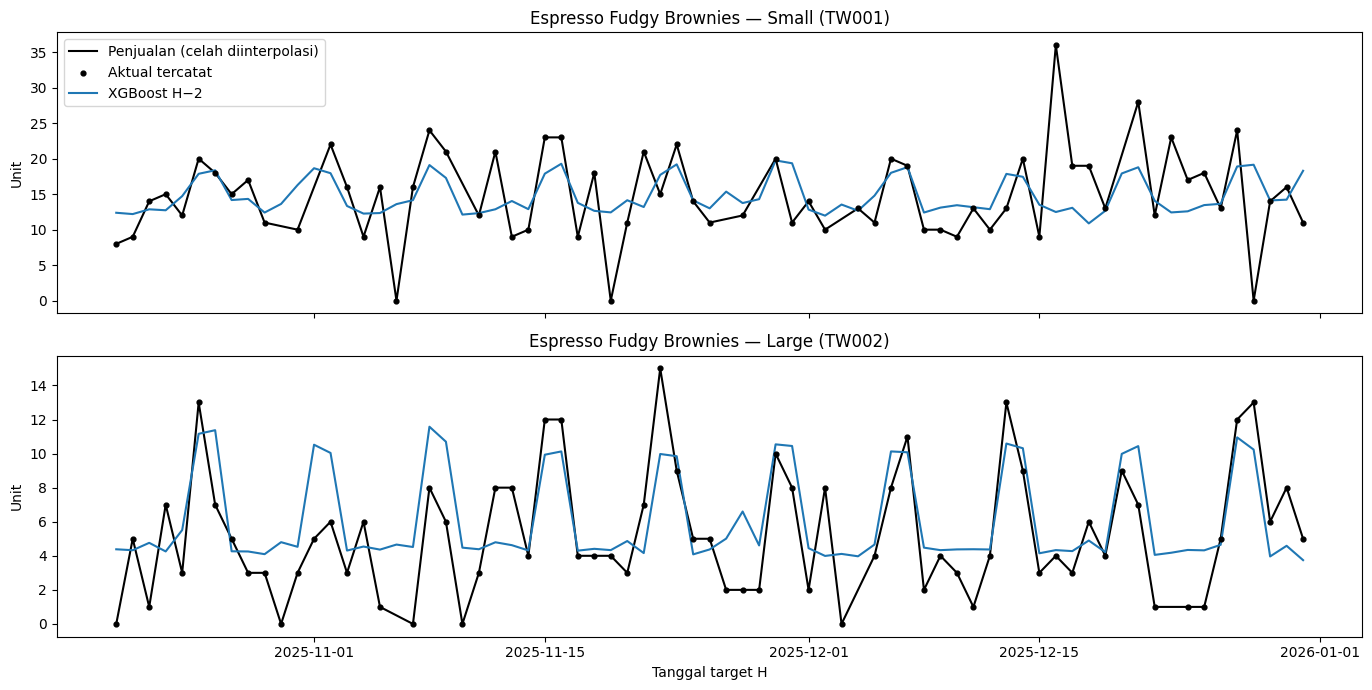

In [62]:
# Grafik model terpilih untuk brownies
# Membandingkan model terpilih dengan garis interpolasi dan titik aktual untuk dua ukuran brownies.

# Demand tetap ditampilkan per ukuran.
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
variants = catalog.set_index("sku_id")["variant"]

for ax, sku_id in zip(axes, ("TW001", "TW002")):
    series = (
        comparison_clean.loc[comparison_clean["sku_id"].eq(sku_id)]
        .sort_values("order_date")
    )
    variant = variants.at[sku_id]
    observed = series[target].notna()

    ax.plot(
        series["order_date"],
        series["actual_interpolated"],
        color="black",
        label="Penjualan (celah diinterpolasi)",
    )
    ax.scatter(
        series.loc[observed, "order_date"],
        series.loc[observed, target],
        color="black",
        s=12,
        zorder=3,
        label="Aktual tercatat",
    )
    ax.plot(
        series["order_date"],
        series[deployment_model],
        color="tab:blue",
        label=f"{deployment_model} H−2",
    )
    ax.set_title(f"{brownies_name} — {variant} ({sku_id})")
    ax.set_ylabel("Unit")

axes[0].legend()
axes[-1].set_xlabel("Tanggal target H")
fig.tight_layout()
plt.show()

In [63]:
# Perbandingan aktual dan prediksi model demo pada periode test

# 1. Pilih SKU yang ingin diperiksa
sku_view = "TW001"  # Ganti dengan TW002, TW003, dan seterusnya

actual_vs_forecast = (
    comparison_clean.loc[
        comparison_clean["sku_id"].eq(sku_view),
        ["order_date", "forecast_origin", target, deployment_model],
    ]
    .sort_values("order_date")
    .rename(columns={
        target: "Aktual tercatat",
        deployment_model: f"Prediksi {deployment_model}",
    })
    .copy()
)

if actual_vs_forecast.empty:
    raise ValueError(f"SKU {sku_view} tidak ditemukan pada periode test.")

prediction_col = f"Prediksi {deployment_model}"
actual_vs_forecast["Selisih prediksi − aktual"] = (
    actual_vs_forecast[prediction_col] - actual_vs_forecast["Aktual tercatat"]
)
actual_vs_forecast["Error absolut"] = (
    actual_vs_forecast["Selisih prediksi − aktual"].abs()
)

print(f"Aktual vs prediksi H−2 untuk {sku_view}")
display(actual_vs_forecast.round(4))

# 2. Bandingkan MAE keempat model untuk setiap SKU
mae_per_sku = metrics_by_product.pivot(
    index=["sku_id", "product_name", "variant", "N"],
    columns="Model",
    values="MAE",
).reset_index()
mae_per_sku.columns.name = None

mae_per_sku["Model dengan MAE test terendah"] = (
    mae_per_sku[model_names].idxmin(axis=1)
)
mae_per_sku[f"Selisih MAE {deployment_model} − SARIMA"] = (
    mae_per_sku[deployment_model] - mae_per_sku["SARIMA"]
)

display(mae_per_sku.round(4))

Aktual vs prediksi H−2 untuk TW001


,order_date,forecast_origin,Aktual tercatat,Prediksi XGBoost,Selisih prediksi − aktual,Error absolut
0,2025-10-20,2025-10-18,8.0,12.382400,4.3824,4.3824
1,2025-10-21,2025-10-19,9.0,12.196100,3.1961,3.1961
2,2025-10-22,2025-10-20,14.0,12.869000,-1.1310,1.1310
3,2025-10-23,2025-10-21,15.0,12.732500,-2.2675,2.2675
4,2025-10-24,2025-10-22,12.0,14.726500,2.7265,2.7265
...,...,...,...,...,...,...
68,2025-12-27,2025-12-25,24.0,18.902800,-5.0972,5.0972
69,2025-12-28,2025-12-26,0.0,19.148899,19.1489,19.1489
70,2025-12-29,2025-12-27,14.0,14.114400,0.1144,0.1144
71,2025-12-30,2025-12-28,16.0,14.230200,-1.7698,1.7698


,sku_id,product_name,variant,N,MLP,Random Forest,SARIMA,XGBoost,Model dengan MAE test terendah,Selisih MAE XGBoost − SARIMA
0,TW001,Espresso Fudgy Brownies,Small,66,5.4452,4.2929,4.3041,4.2261,XGBoost,-0.0780
1,TW002,Espresso Fudgy Brownies,Large,70,2.7628,2.5282,2.0764,2.2325,SARIMA,0.1561
2,TW003,Blueberry Cheese Crumble,Standard,72,4.2944,3.4265,3.3713,3.4798,SARIMA,0.1084
3,TW004,Korean Garlic Creamcheese,Standard,71,3.5265,2.8002,2.7832,2.8007,SARIMA,0.0174
4,TW005,Cranberry Walnut Creamcheese,Standard,72,5.3025,3.3132,3.2709,2.9843,XGBoost,-0.2866
5,TW006,Dusty Choco Hazelnut,Standard,70,4.4122,3.0489,2.9340,2.9635,SARIMA,0.0294
6,TW007,Paket Alit,Package,72,2.0610,1.7963,1.6354,1.5727,XGBoost,-0.0628
7,TW008,Salt Bread Original,Standard,72,5.0654,4.1818,4.0668,4.1577,SARIMA,0.0909
8,TW009,Sei Cheese Salt Bread,Standard,69,4.3970,3.4936,3.3298,3.3601,SARIMA,0.0303
9,TW010,Shokupan Loaf,Standard,69,4.6263,4.1013,3.9026,3.9858,SARIMA,0.0833


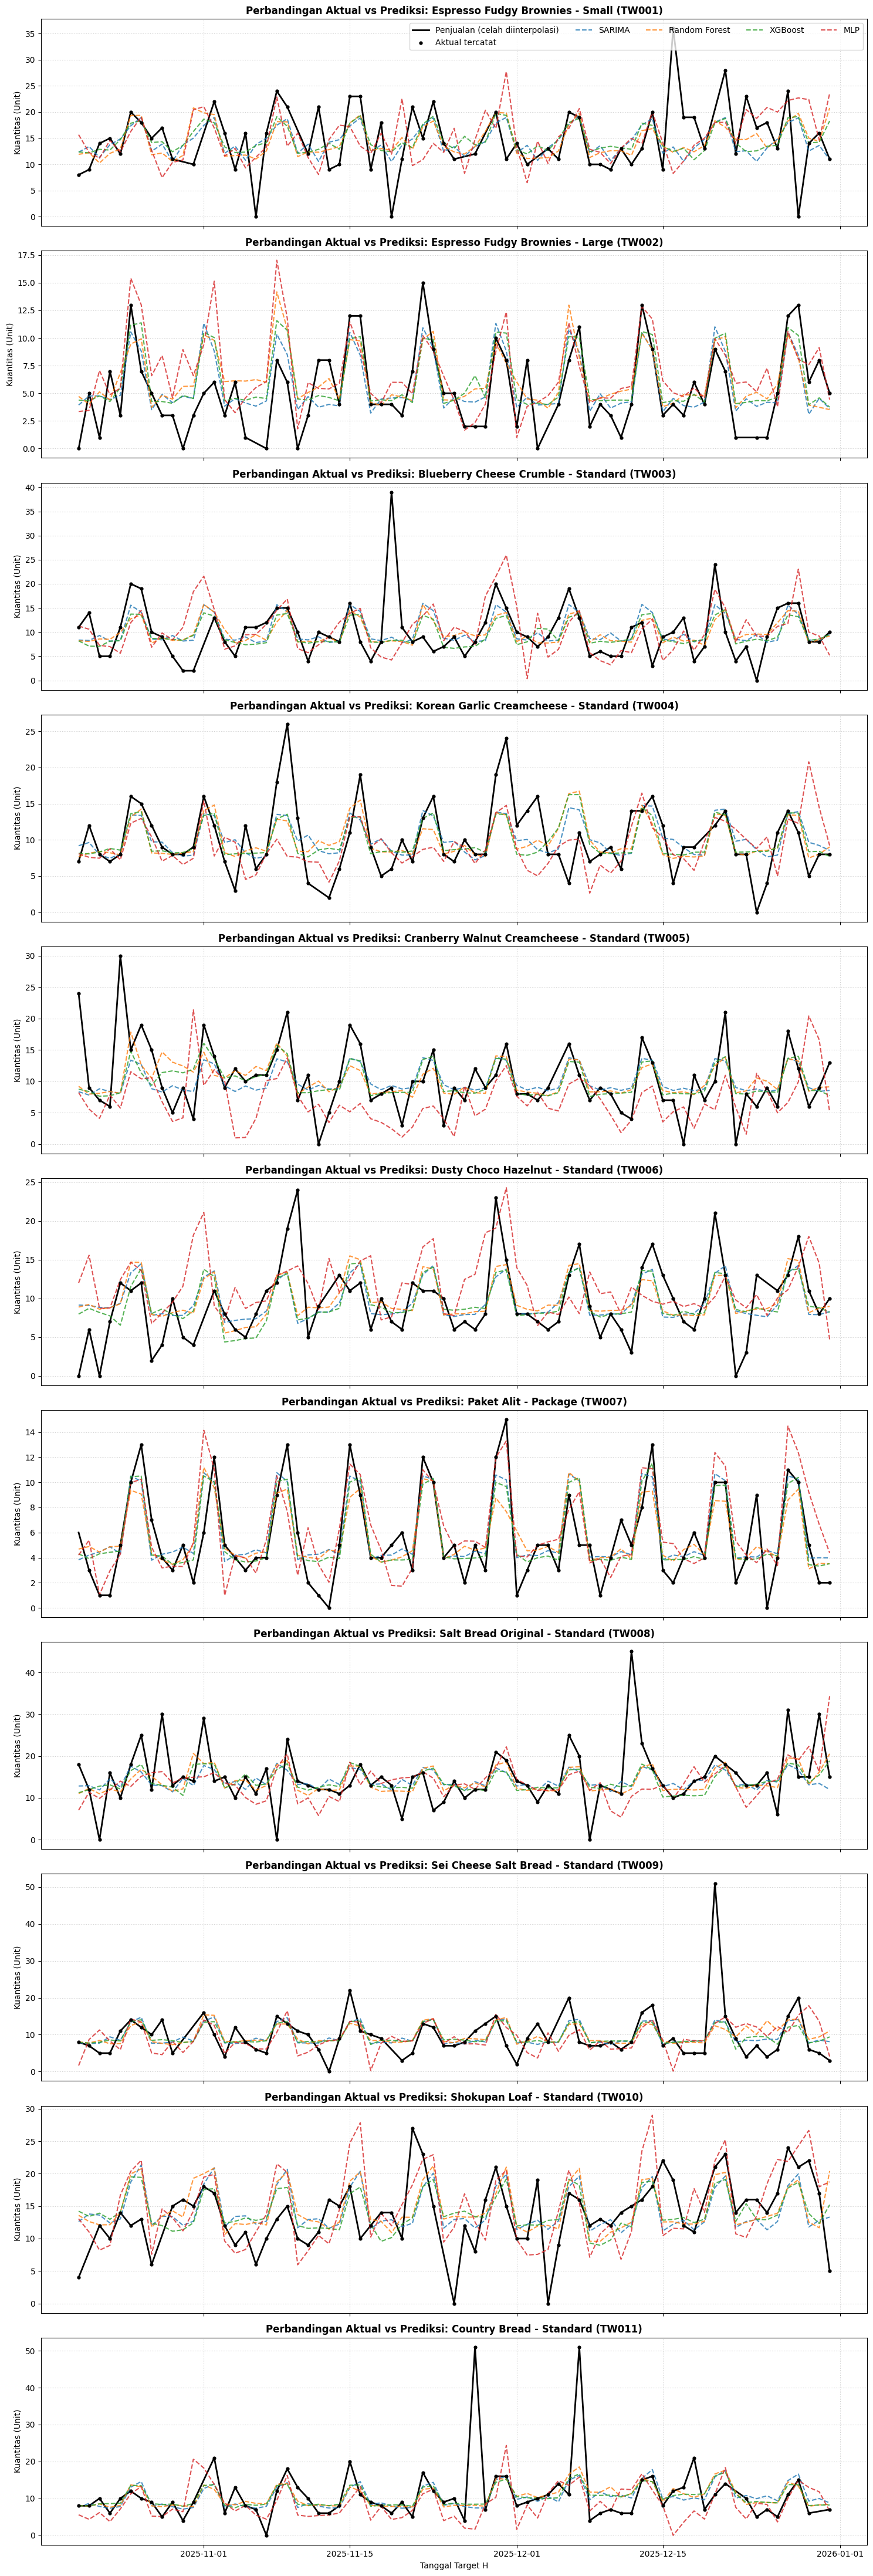

In [64]:
# Grafik perbandingan semua SKU
# Menampilkan aktual dan prediksi model per SKU pada tanggal target yang sama.

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Mempersiapkan data visualisasi menggunakan tabel comparison_clean
  # Kita akan memplot beberapa sampel produk dari TW001 s.d TW011

unique_skus = sorted(comparison_clean["sku_id"].unique())
fig, axes = plt.subplots(
    len(unique_skus), 1,
    figsize=(15, 4 * len(unique_skus)),
    sharex=True,
    squeeze=False,
)
axes = axes[:, 0]
sku_catalog = catalog.set_index("sku_id")

# 2. Mengambil data untuk satu SKU
sku_catalog = catalog.set_index("sku_id")

for ax, sku in zip(axes, unique_skus):
    # Ambil subset data untuk produk tertentu
    sub_data = (
        comparison_clean.loc[comparison_clean["sku_id"].eq(sku)]
        .sort_values("order_date")
    )
    product_name = sku_catalog.at[sku, "product_name"]
    variant = sku_catalog.at[sku, "variant"]
    observed = sub_data[target].notna()

# 3. Menggambar garis interpolasi dan titik aktual
    ax.plot(
        sub_data["order_date"],
        sub_data["actual_interpolated"],
        color="black",
        linewidth=2,
        label="Penjualan (celah diinterpolasi)",
        )
    ax.scatter(
        sub_data.loc[observed, "order_date"],
        sub_data.loc[observed, target],
        color="black",
        s=12,
        zorder=4,
        label="Aktual tercatat",
    )

    # 4. Menggambar prediksi dan memberi judul panel
    for model in model_names:
        ax.plot(sub_data['order_date'], sub_data[model], label=model, alpha=0.8, linestyle='--')

    ax.set_title(f"Perbandingan Aktual vs Prediksi: {product_name} - {variant} ({sku})", fontsize=12, fontweight='bold')
    ax.set_ylabel("Kuantitas (Unit)")
    ax.grid(True, linestyle=':', alpha=0.6)
    if ax == axes[0]:
        ax.legend(loc='upper right', ncol=5)

axes[-1].set_xlabel("Tanggal Target H")
plt.tight_layout()
plt.show()

In [65]:
# ACTUAL VS PREDICTED - ALL MODELS FOR DATASET
# Menampilkan aktual tercatat, prediksi empat model, dan baseline H−7.

table_cols = [
    "Random Forest",
    "XGBoost",
    "MLP",
    "SARIMA",
    "Seasonal Naive"
]

comparison = predictions[
    [
        "order_date",
        "forecast_origin",
        "sku_id",
        "quantity_clean",
        *model_cols
    ]
].copy()

comparison = comparison.rename(
    columns={"quantity_clean": "Actual"}
)

comparison = comparison.sort_values(
    ["sku_id", "order_date"]
).reset_index(drop=True)

# Tampilkan hasil dengan 2 angka desimal
display(comparison.head(20).round(2))

,order_date,forecast_origin,sku_id,Actual,SARIMA,Random Forest,XGBoost,MLP
0,2025-10-20,2025-10-18,TW001,8.0,12.33,11.92,12.380000,15.67
1,2025-10-21,2025-10-19,TW001,9.0,13.41,12.23,12.200000,12.28
2,2025-10-22,2025-10-20,TW001,14.0,11.34,10.27,12.870000,11.17
3,2025-10-23,2025-10-21,TW001,15.0,13.76,12.10,12.730000,14.59
4,2025-10-24,2025-10-22,TW001,12.0,14.86,12.95,14.730000,12.37
5,2025-10-25,2025-10-23,TW001,20.0,17.38,19.34,17.870001,16.30
6,2025-10-26,2025-10-24,TW001,18.0,18.97,19.37,18.360001,19.08
7,2025-10-27,2025-10-25,TW001,15.0,12.50,11.84,14.170000,12.68
8,2025-10-28,2025-10-26,TW001,17.0,13.88,12.17,14.340000,7.48
9,2025-10-29,2025-10-27,TW001,11.0,10.56,10.55,12.410000,10.38


In [66]:
# Ekspor backtest
# Menyimpan riwayat prediksi tingkat SKU dan agregasi stok sebagai CSV.

# Hasil historis untuk audit, terpisah dari publikasi prediksi mendatang.
predictions.to_csv("backtest_demand_per_sku.csv", index=False)
stock_backtest.to_csv("backtest_stok_per_produk.csv", index=False)

In [67]:
# Pelatihan final
# Melatih ulang model dengan riwayat yang tersedia sampai tanggal terakhir dataset.

final_origin = panel["order_date"].max()
final_target_date = final_origin + pd.Timedelta(days=HORIZON)
final_train = feature_panel.dropna(subset=[target])

final_ml_models = {}
for name, evaluation_pipeline in models.items():
    final_ml_models[name] = clone(evaluation_pipeline).fit(
        final_train[features], final_train[target]
    )

final_sarima_models = {}
final_sarima_status = []
for sku_id in catalog["sku_id"]:
    fitted_final = SARIMAX(
        daily_sales[sku_id],
        order=(1, 1, 1),
        seasonal_order=(1, 1, 1, 7),
    ).fit(disp=False, maxiter=200, low_memory=True)
    final_sarima_models[sku_id] = fitted_final
    final_sarima_status.append({
        "sku_id": sku_id,
        "converged": bool(fitted_final.mle_retvals["converged"]),
    })

print(f"Pelatihan final ML: {len(final_train)} label valid sampai {final_origin:%Y-%m-%d}")
display(pd.DataFrame(final_sarima_status))

Pelatihan final ML: 3838 label valid sampai 2025-12-31


,sku_id,converged
0,TW001,True
1,TW002,True
2,TW003,True
3,TW004,True
4,TW005,True
5,TW006,True
6,TW007,True
7,TW008,True
8,TW009,True
9,TW010,True


In [68]:
# Forecast dua hari ke depan
# Membentuk tanggal dan fitur mendatang lalu menghasilkan prediksi final per SKU.

# Sertakan kedua tanggal mendatang agar shift tetap berarti hari kalender.
future_dates = pd.date_range(
    final_origin + pd.Timedelta(days=1), final_target_date, freq="D"
)
future_panel = pd.MultiIndex.from_product(
    [future_dates, catalog["sku_id"]], names=sku_day_key
).to_frame(index=False)
future_panel[target] = np.nan
forecasting_panel = pd.concat(
    [panel[sku_day_key + [target]], future_panel],
    ignore_index=True,
)
final_features = build_h2_features(forecasting_panel)
final_features = final_features.loc[final_features["order_date"].eq(final_target_date)].copy()
assert final_features["forecast_origin"].eq(final_origin).all()

final_forecast = final_features[["order_date", "forecast_origin", "sku_id"]].copy()
final_forecast["SARIMA"] = final_forecast["sku_id"].map(
    {sku_id: max(0.0, float(model.forecast(steps=HORIZON).loc[final_target_date]))
     for sku_id, model in final_sarima_models.items()}
)
for name, pipeline in final_ml_models.items():
    final_forecast[name] = np.maximum(0, pipeline.predict(final_features[features]))
final_forecast = final_forecast.merge(catalog, on="sku_id", validate="one_to_one")
assert np.isfinite(final_forecast[model_names].to_numpy()).all()
display(final_forecast[["order_date", "forecast_origin", "sku_id", "product_name", "variant", *model_names]])

,order_date,forecast_origin,sku_id,product_name,variant,SARIMA,Random Forest,XGBoost,MLP
0,2026-01-02,2025-12-31,TW001,Espresso Fudgy Brownies,Small,14.735163,14.116225,15.543439,17.516110
1,2026-01-02,2025-12-31,TW002,Espresso Fudgy Brownies,Large,4.225154,4.194971,3.962362,0.000000
2,2026-01-02,2025-12-31,TW003,Blueberry Cheese Crumble,Standard,8.355828,7.985211,8.145978,5.594783
3,2026-01-02,2025-12-31,TW004,Korean Garlic Creamcheese,Standard,7.778210,8.170179,8.502492,2.894742
4,2026-01-02,2025-12-31,TW005,Cranberry Walnut Creamcheese,Standard,8.622088,9.065999,8.091474,3.482411
5,2026-01-02,2025-12-31,TW006,Dusty Choco Hazelnut,Standard,9.629049,8.472949,8.400947,10.012670
6,2026-01-02,2025-12-31,TW007,Paket Alit,Package,4.185327,3.464794,3.927412,1.645271
7,2026-01-02,2025-12-31,TW008,Salt Bread Original,Standard,13.723042,17.034209,14.886108,9.829217
8,2026-01-02,2025-12-31,TW009,Sei Cheese Salt Bread,Standard,7.933990,10.201466,8.526092,10.774819
9,2026-01-02,2025-12-31,TW010,Shokupan Loaf,Standard,13.471522,13.616931,14.070903,8.517386


In [69]:
# Simpan dan uji model
# Menyimpan model serta konteks forecast dan memeriksa kesamaan hasil setelah dimuat ulang.

# Simpan model terlatih dan konteks yang diperlukan untuk memuatnya kembali.
from importlib.metadata import version
import joblib

model_path = Path("Tewiwi_H-2_Per_SKU.joblib")
model_bundle = {
    "format_version": 2,
    "horizon_days": HORIZON,
    "trained_through": final_origin,
    "features": features,
    "target": target,
    "catalog": catalog,
    "recent_history": panel.loc[
        panel["order_date"].gt(final_origin - pd.Timedelta(days=14)),
        sku_day_key + [target],
    ].copy(),
    "ml_models": final_ml_models,
    "sarima_models": final_sarima_models,
    "holdout_metrics": metrics,
    "holdout_metrics_by_sku": metrics_by_product,
    "holdout_metrics_by_stock_product": stock_metrics,
    "forecast": final_forecast,
    "library_versions": {
        package: version(package) for package in (
            "numpy", "pandas", "scikit-learn", "scipy", "statsmodels", "xgboost", "joblib"
        )
    },
}
joblib.dump(model_bundle, model_path, compress=3)
reloaded = joblib.load(model_path)

for name, pipeline in reloaded["ml_models"].items():
    np.testing.assert_allclose(
        np.maximum(0, pipeline.predict(final_features[reloaded["features"]])),
        final_forecast[name].to_numpy(),
    )
for sku_id, model in reloaded["sarima_models"].items():
    value = model.forecast(steps=HORIZON).loc[final_target_date]
    expected = final_forecast.loc[final_forecast["sku_id"].eq(sku_id), "SARIMA"].item()
    np.testing.assert_allclose(max(0.0, float(value)), expected)

print(f"Model tersimpan dan lolos uji muat ulang: {model_path.name}")

Model tersimpan dan lolos uji muat ulang: Tewiwi_H-2_Per_SKU.joblib


In [70]:
# Ekspor pipeline XGBoost untuk inferensi di backend
xgboost_bundle = {
    "model_name": "XGBoost",
    "model_version": "tewiwi-xgboost-h2-v1",
    "pipeline": final_ml_models["XGBoost"],
    "features": features,
    "horizon_days": HORIZON,
    "target": target,
    "catalog": catalog,
    "trained_through": final_origin,
    "library_versions": model_bundle["library_versions"],
}

joblib.dump(xgboost_bundle, "tewiwi_xgboost_h2.joblib", compress=3)

['tewiwi_xgboost_h2.joblib']

# Publikasi untuk website

In [72]:
# Ekspor forecast model terpilih
# Membuat JSON berisi prediksi per SKU dan kebutuhan stok per produk dari selected_model.

def make_payload(sku_forecast, catalog, model_name):
    """Build both website views from one date and the same set of SKU predictions."""
    demand = sku_forecast[
        ["order_date", "forecast_origin", "sku_id", model_name]
    ].rename(columns={model_name: "forecast_units"}).merge(
        catalog, on="sku_id", how="left", validate="one_to_one"
    )
    if set(demand["sku_id"]) != set(catalog["sku_id"]):
        raise ValueError("Forecast harus memuat semua SKU dalam katalog.")
    if demand[["order_date", "forecast_origin"]].drop_duplicates().shape[0] != 1:
        raise ValueError("Publikasikan satu tanggal target dan satu origin per berkas.")
    if not np.isfinite(demand["forecast_units"]).all() or demand["forecast_units"].lt(0).any():
        raise ValueError("Forecast harus berisi angka nonnegatif yang valid.")

    demand = demand.sort_values("sku_id")
    demand_rows = [
        {
            "sku_id": row.sku_id,
            "product_name": row.product_name,
            "variant": None if pd.isna(row.variant) else row.variant,
            "stock_product_id": row.stock_product_id,
            "forecast_units": float(row.forecast_units),
        }
        for row in demand.itertuples(index=False)
    ]
    stock_rows = [
        {
            "stock_product_id": stock_id,
            "product_name": group["product_name"].iloc[0],
            "sku_ids": group["sku_id"].tolist(),
            "gross_demand_units": float(group["forecast_units"].sum()),
        }
        for stock_id, group in demand.groupby("stock_product_id", sort=True)
    ]
    origin = demand["forecast_origin"].iloc[0]
    target_date = demand["order_date"].iloc[0]
    return {
        "schema_version": 1,
        "model": model_name,
        "forecast_origin": origin.strftime("%Y-%m-%d"),
        "target_date": target_date.strftime("%Y-%m-%d"),
        "horizon_days": (target_date - origin).days,
        "demand_by_sku": demand_rows,
        "stock_by_product": stock_rows,
    }

import json

website_model = deployment_model
payload = make_payload(final_forecast, catalog, website_model)
Path("forecast_h2.json").write_text(
    json.dumps(payload, ensure_ascii=False, indent=2, allow_nan=False) + "\n", encoding="utf-8"
)
display(pd.DataFrame(payload["demand_by_sku"]))
display(pd.DataFrame(payload["stock_by_product"]))

,sku_id,product_name,variant,stock_product_id,forecast_units
0,TW001,Espresso Fudgy Brownies,Small,TW001,15.543439
1,TW002,Espresso Fudgy Brownies,Large,TW001,3.962362
2,TW003,Blueberry Cheese Crumble,Standard,TW003,8.145978
3,TW004,Korean Garlic Creamcheese,Standard,TW004,8.502492
4,TW005,Cranberry Walnut Creamcheese,Standard,TW005,8.091474
5,TW006,Dusty Choco Hazelnut,Standard,TW006,8.400947
6,TW007,Paket Alit,Package,TW007,3.927412
7,TW008,Salt Bread Original,Standard,TW008,14.886108
8,TW009,Sei Cheese Salt Bread,Standard,TW009,8.526092
9,TW010,Shokupan Loaf,Standard,TW010,14.070903


,stock_product_id,product_name,sku_ids,gross_demand_units
0,TW001,Espresso Fudgy Brownies,"[TW001, TW002]",19.505800
1,TW003,Blueberry Cheese Crumble,[TW003],8.145978
2,TW004,Korean Garlic Creamcheese,[TW004],8.502492
3,TW005,Cranberry Walnut Creamcheese,[TW005],8.091474
4,TW006,Dusty Choco Hazelnut,[TW006],8.400947
5,TW007,Paket Alit,[TW007],3.927412
6,TW008,Salt Bread Original,[TW008],14.886108
7,TW009,Sei Cheese Salt Bread,[TW009],8.526092
8,TW010,Shokupan Loaf,[TW010],14.070903
9,TW011,Country Bread,[TW011],8.118745


In [73]:
# Inferensi XGBoost untuk slot pengiriman demo

# 1. Ambil definisi slot dari aturan alokasi yang dipakai saat backtest
demo_delivery_date = pd.Timestamp("2026-01-02")

demo_calendar = build_slot_calendar(
    demo_delivery_date - pd.Timedelta(days=7),
    demo_delivery_date,
)
demo_slot_rows = demo_calendar.loc[
    demo_calendar["delivery_date"].eq(demo_delivery_date)
]

if len(demo_slot_rows) != 1:
    raise ValueError("Tanggal demo harus cocok dengan satu slot pengiriman.")

demo_slot = demo_slot_rows.iloc[0]
demo_order_dates = pd.date_range(
    demo_slot["order_window_start"],
    demo_slot["order_window_end"],
    freq="D",
)
demo_slot_origin = demo_slot["slot_forecast_origin"]

# Gunakan pipeline yang sama dengan backtest harian.
demo_model_name = "XGBoost"
demo_pipeline = models[demo_model_name]
demo_trained_through = train["order_date"].max()

# 2. Buat forecast H−2 untuk masing-masing tanggal pemesanan
demo_daily_frames = []

for order_day in demo_order_dates:
    daily_origin = order_day - pd.Timedelta(days=HORIZON)

    if not demo_trained_through <= daily_origin <= demo_slot_origin:
        raise ValueError(
            f"Model atau forecast harian belum tersedia pada "
            f"tanggal yang diperlukan untuk {order_day:%Y-%m-%d}."
        )

    daily_history = panel.loc[
        panel["order_date"].le(daily_origin),
        sku_day_key + [target],
    ].copy()

    if daily_history["order_date"].max() != daily_origin:
        raise ValueError(
            f"Kalender riwayat belum mencakup {daily_origin:%Y-%m-%d}."
        )

    # Lengkapi kalender hingga tanggal target agar lag tetap dihitung
    # berdasarkan hari kalender.
    future_dates = pd.date_range(
        daily_origin + pd.Timedelta(days=1),
        order_day,
        freq="D",
    )
    future_rows = pd.MultiIndex.from_product(
        [future_dates, catalog["sku_id"]],
        names=sku_day_key,
    ).to_frame(index=False)
    future_rows[target] = np.nan

    inference_panel = pd.concat(
        [daily_history, future_rows],
        ignore_index=True,
    )

    inference_features = build_h2_features(inference_panel)
    target_rows = inference_features.loc[
        inference_features["order_date"].eq(order_day)
    ].copy()

    daily_forecast = target_rows[
        ["order_date", "forecast_origin", "sku_id"]
    ].copy()
    daily_forecast[demo_model_name] = np.maximum(
        0,
        demo_pipeline.predict(target_rows[features]),
    )
    demo_daily_frames.append(daily_forecast)

demo_daily_forecast = pd.concat(demo_daily_frames, ignore_index=True)

# 3. Periksa bahwa seluruh kombinasi tanggal dan SKU tersedia tepat sekali
expected_pairs = pd.MultiIndex.from_product(
    [demo_order_dates, catalog["sku_id"]],
    names=["order_date", "sku_id"],
)
actual_pairs = pd.MultiIndex.from_frame(
    demo_daily_forecast[["order_date", "sku_id"]]
)

if not actual_pairs.is_unique or set(actual_pairs) != set(expected_pairs):
    raise ValueError("Cakupan forecast harian untuk slot demo belum lengkap.")

if not np.isfinite(demo_daily_forecast[demo_model_name]).all():
    raise ValueError("Forecast slot memuat nilai prediksi yang tidak valid.")

# 4. Jumlahkan prediksi harian menjadi satu estimasi per SKU untuk slot
demo_slot_forecast = (
    demo_daily_forecast
    .groupby("sku_id", as_index=False)[demo_model_name]
    .sum()
    .rename(columns={demo_model_name: "forecast_units"})
    .assign(
        delivery_date=demo_delivery_date,
        slot_forecast_origin=demo_slot_origin,
    )
)

print(f"Slot pengiriman: {demo_delivery_date:%Y-%m-%d}")
print(f"Estimasi slot diterbitkan: {demo_slot_origin:%Y-%m-%d}")
print(f"Forecast harian: {len(demo_daily_forecast)} baris")
display(demo_slot_forecast.round(4))

Slot pengiriman: 2026-01-02
Estimasi slot diterbitkan: 2025-12-31
Forecast harian: 33 baris


,sku_id,forecast_units,delivery_date,slot_forecast_origin
0,TW001,47.106800,2026-01-02,2025-12-31
1,TW002,12.907100,2026-01-02,2025-12-31
2,TW003,26.754999,2026-01-02,2025-12-31
3,TW004,23.963800,2026-01-02,2025-12-31
4,TW005,24.671700,2026-01-02,2025-12-31
5,TW006,25.542900,2026-01-02,2025-12-31
6,TW007,11.216300,2026-01-02,2025-12-31
7,TW008,47.580799,2026-01-02,2025-12-31
8,TW009,26.404699,2026-01-02,2025-12-31
9,TW010,39.899899,2026-01-02,2025-12-31


In [74]:
# Ekspor contoh respons slot dan pipeline XGBoost demo

import json
import joblib
from importlib.metadata import version

# 1. Bentuk kontrak respons untuk dashboard admin
demo_model_version = "tewiwi-xgb-h2-demo-v1"

demo_slot_payload = {
    "schema_version": 1,
    "model": demo_model_name,
    "model_version": demo_model_version,
    "is_simulation": True,
    "delivery_date": demo_delivery_date.strftime("%Y-%m-%d"),
    "slot_forecast_origin": demo_slot_origin.strftime("%Y-%m-%d"),
    "order_window_start": demo_order_dates[0].strftime("%Y-%m-%d"),
    "order_window_end": demo_order_dates[-1].strftime("%Y-%m-%d"),
    "order_cutoff_days": SIMULATED_ORDER_CUTOFF_DAYS,
    "daily_forecast_horizon_days": HORIZON,
    "order_days_forecasted": len(demo_order_dates),
    "sku_count": len(demo_slot_forecast),
    "demand_by_sku": [
        {
            "sku_id": row.sku_id,
            "forecast_units": float(row.forecast_units),
        }
        for row in demo_slot_forecast.itertuples(index=False)
    ],
}

Path("forecast_slot_demo.json").write_text(
    json.dumps(demo_slot_payload, ensure_ascii=False, indent=2, allow_nan=False)
    + "\n",
    encoding="utf-8",
)

# 2. Simpan pipeline yang digunakan untuk menghasilkan contoh respons
demo_bundle = {
    "model": demo_model_name,
    "model_version": demo_model_version,
    "pipeline": demo_pipeline,
    "trained_through": demo_trained_through.strftime("%Y-%m-%d"),
    "features": list(features),
    "target": target,
    "horizon_days": HORIZON,
    "delivery_weekdays": DELIVERY_WEEKDAYS,
    "order_cutoff_days": SIMULATED_ORDER_CUTOFF_DAYS,
    "catalog": catalog.copy(),
    "library_versions": {
        name: version(name)
        for name in ("numpy", "pandas", "scikit-learn", "scipy", "xgboost", "joblib")
    },
}

joblib.dump(demo_bundle, "tewiwi_xgboost_demo.joblib", compress=3)

print("Contoh respons: forecast_slot_demo.json")
print("Pipeline inferensi: tewiwi_xgboost_demo.joblib")

Contoh respons: forecast_slot_demo.json
Pipeline inferensi: tewiwi_xgboost_demo.joblib


In [75]:
# Ekspor backtest slot untuk dokumentasi dan demo
slot_backtest.rename(
    columns={target: "actual_units_simulated"}
).to_csv("backtest_slot_pengiriman_simulasi.csv", index=False)

In [71]:
# Buat daftar versi dependensi model
from importlib.metadata import version
from pathlib import Path

packages = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "xgboost",
    "joblib",
]

requirements = [f"{package}=={version(package)}" for package in packages]
requirements.extend(["fastapi", "uvicorn"])

Path("requirements.txt").write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8",
)

print(Path("requirements.txt").read_text())

numpy==2.4.6
pandas==2.2.3
scipy==1.16.3
scikit-learn==1.6.1
xgboost==3.4.1
joblib==1.6.0
fastapi
uvicorn

